<a href="https://colab.research.google.com/github/farrelrassya/Build-a-Large-Language-Model-From-Scratch/blob/main/07.Fine_Tuning_To_Follow_Instructions.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Chapter 7 -- Fine-tuning to Follow Instructions

*Build a Large Language Model (From Scratch)* -- Sebastian Raschka (Manning, 2024)

**Technical edition -- setiap output berasal dari run riil di Colab (Tesla T4); tidak ada output yang difabrikasi.**

Sampai Chapter 5, model GPT kita adalah mesin pelengkap teks: diberi awal kalimat, ia melanjutkan. Itu kemampuan yang mengesankan, tapi belum membuatnya jadi asisten. Kalau kita mengetik "Ubah kalimat ini ke passive voice", model pretrained tidak mengerjakannya; ia memperlakukan perintah itu sebagai teks lain yang perlu diteruskan. Bab terakhir buku ini menutup celah itu dengan *instruction fine-tuning*: GPT-2 medium (355 juta parameter) dilatih lagi dengan 1,100 contoh pasangan instruksi dan jawaban, memakai loss yang sama persis dengan pretraining. Yang berubah hanya isi teksnya.

**Hasilnya terlihat jelas di run ini.** Pada instruksi validasi pertama, model pretrained hanya mengulang kalimat input lalu mulai menyalin instruksinya lagi. Sesudah 232 langkah training (2 epoch, 9.03 menit di T4), model yang sama menjawab "The meal is cooked every day by the chef." -- persis jawaban yang dicetak di buku. Loss validasi pada 5 batch yang sama turun dari 3.762 ke 0.6551, dan dari 110 instruksi test yang belum pernah dilihatnya, 109 dijawab lalu diakhiri sendiri oleh model.

**Run ini juga ternyata sangat dekat dengan buku.** Loss awal validasi identik sampai digit terakhir dengan angka cetak, empat baris pertama log training identik dengan buku, dan tiga jawaban test pertama sama kata demi kata dengan contoh di buku. Di langkah-langkah berikutnya yang dicetak buku, angkanya bergeser di desimal ketiga. Itu wajar untuk training di GPU berbeda, dan notebook ini mengukur selisihnya alih-alih menyembunyikannya.

Kode bab adalah listing resmi dari repo [`rasbt/LLMs-from-scratch`](https://github.com/rasbt/LLMs-from-scratch) (Apache-2.0), commit `cdbd33e`, verbatim dan berurutan seperti buku. Beberapa sel bergantung pada environment -- misalnya butuh TensorFlow atau aplikasi Ollama -- sehingga dijalankan lewat *harness*: source resminya tetap utuh, dan bila gagal, traceback aslinya dicetak tanpa menghentikan Run all. Sel tambahan yang bukan dari buku ditandai komentar di baris pertama. Saat notebook disimpan, editor Colab memangkas spasi di akhir baris pada empat sel kode; isi kodenya tidak berubah.

| Under the hood | Pertanyaan | Hasil di run ini |
|---|---|---|
| **UTH 1** -- Ekonomi collate | Seberapa hemat padding per batch, dan berapa porsi loss yang jatuh ke teks prompt? | Padding per batch 12,375 token vs 32,071 bila dipad ke contoh terpanjang (2.6x lebih hemat); 928/928 baris target menyimpan tepat satu token end-of-text; 66.1% posisi target adalah teks prompt |
| **UTH 2** -- Anatomi loss | Bagian teks mana yang sebenarnya dipelajari model? | Cross-entropy kalimat pembuka Alpaca turun dari 4.255 ke 0.000 (dihafal total), isi jawaban dari 2.780 ke 1.118; sesudah training 62.0% sisa loss ada di teks instruksi |
| **UTH 3** -- Belajar berhenti | Apakah model belajar kapan jawabannya selesai? | Peluang token akhir sesudah jawaban benar naik dari 0.0169 ke 0.9558; 109/110 jawaban test berhenti sendiri, satu terjebak pengulangan sampai batas 256 token |
| **UTH 4** -- Kalibrasi juri | Seberapa bisa dipercaya skor LLM juri? | Tidak dijalankan: butuh Ollama lokal, yang tidak ada di Colab |

## Setup

Notebook ini dirancang agar *Run all* di Colab berjalan tanpa campur tangan. Sebelum menyentuh isi bab, dua sel pertama menyiapkan panggung: yang pertama memasang paket yang belum ada, yang kedua menetapkan pilihan run dan menyiapkan harness untuk sel-sel yang hasilnya bergantung environment.

Pilihan run yang tersedia, dan nilai yang dipakai run ini:

| Flag | Nilai di run ini | Artinya |
|---|---|---|
| `RUN_EXERCISES` | `False` | Latihan 7.1/7.2/7.4 tidak dilatih ulang. Set `True` untuk melatih tiga varian GPT-2 medium tambahan (GPU sangat disarankan) |
| `USE_RESUMABLE_TRAINING` | `True` | Training menulis checkpoint di setiap akhir epoch dan bisa dilanjutkan bila sesi putus |
| `USE_GOOGLE_DRIVE` | `False` | Checkpoint disimpan di disk VM Colab, yang hilang bila runtime di-reset; `True` memindahkannya ke Google Drive |
| `RUN_ALT_JUDGE` | `False` | Eksperimen juri alternatif lewat Ollama lokal (bukan juri buku) |

Untuk menjalankan ulang: buka di Colab, pilih *Runtime > Change runtime type > T4 GPU*, lalu *Run all*. Run ini memakan 17.4 menit dari sel pertama sampai terakhir, termasuk mengunduh checkpoint TensorFlow 1.42 GB untuk jalur bobot versi buku. Training GPT-2 medium dengan AdamW butuh sekitar 6.5 GB untuk bobot, gradien, dan state optimizer saja, dan setiap checkpoint yang bisa di-resume berukuran 4.98 GB di disk.

In [ ]:
# Sel tambahan: bootstrap dependensi sebelum import apa pun (hanya memasang yang belum ada)
import importlib.util, subprocess, sys

required = ["torch", "tiktoken", "requests", "matplotlib", "tqdm", "psutil", "safetensors", "numpy"]
missing = [pkg for pkg in required if importlib.util.find_spec(pkg) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
print("python   :", sys.version.split()[0])
print("dipasang :", ", ".join(missing) if missing else "tidak ada (semua sudah terpasang)")

python   : 3.13.15
dipasang : tidak ada (semua sudah terpasang)


Semua paket ternyata sudah ada di image Colab, jadi tidak ada yang dipasang. Perhatikan bahwa sel ini hanya *memeriksa* keberadaan paket dengan `find_spec`, tanpa meng-import satu pun. Itu disengaja: `import torch` atau `import requests` diam-diam ikut memuat modul `urllib.request`, dan modul itulah yang menentukan nasib listing 7.1 di bawah. Kita ingin listing itu bertemu kernel yang belum "tercemar".

In [ ]:
# Sel tambahan: konfigurasi run dan harness errata (sebelum import torch/requests -- lihat Errata #2)
import linecache, os, sys, traceback

import time

RUN_EXERCISES = False           # True: latih latihan 7.1/7.2/7.4 (estimasi belum diukur: +20-25 menit di T4)
USE_RESUMABLE_TRAINING = True   # checkpoint di setiap boundary epoch (model + AdamW + RNG), resume otomatis
USE_GOOGLE_DRIVE = False        # True (Colab): checkpoint di Google Drive, bertahan bila runtime di-reset
CHECKPOINT_DIR = "ch07_checkpoints"   # atau path pilihan sendiri
RUN_ALT_JUDGE = False           # eksperimen juri alternatif via Ollama lokal (bukan juri buku)
ALT_JUDGE_MODEL = "qwen3.5:9b"  # model juri alternatif; butuh `think: False` bila model punya mode thinking
DOWNLOAD_ARTIFACTS = False      # True (Colab): unduh ringkasan dan respons JSON otomatis di akhir
SUMMARY_FILE = "ch07_colab_summary.json"
RESPONSES_FILE = "ch07_colab_responses.json"
ERRATA_LOG = {}
TIMERS = {"run_start": time.time()}

if USE_GOOGLE_DRIVE and "google.colab" in sys.modules:
    from google.colab import drive
    drive.mount("/content/drive")
    CHECKPOINT_DIR = "/content/drive/MyDrive/ch07_checkpoints"


def run_listing(label, src):
    """Jalankan source listing apa adanya di namespace notebook. Bila gagal: traceback riil dicetak, Run all berlanjut."""
    if src.startswith("\n") and src.endswith("\n"):
        src = src[1:-1]                      # baris pembuka/penutup string bukan bagian listing
    fname = f"<{label}>"
    linecache.cache[fname] = (len(src), None, src.splitlines(True), fname)
    try:
        exec(compile(src, fname, "exec"), globals())
    except Exception as e:
        traceback.print_exc()
        ERRATA_LOG[label] = f"{type(e).__name__}: {e}"
        print(f"\n[harness] {label}: {type(e).__name__} -- traceback riil di atas; Run all berlanjut.")
    else:
        ERRATA_LOG[label] = "OK"
        print(f"[harness] {label}: selesai tanpa error di environment ini.")


print("konfigurasi:", {k: globals()[k] for k in ["RUN_EXERCISES", "USE_RESUMABLE_TRAINING", "USE_GOOGLE_DRIVE",
                                                 "CHECKPOINT_DIR", "RUN_ALT_JUDGE", "DOWNLOAD_ARTIFACTS"]})

konfigurasi: {'RUN_EXERCISES': False, 'USE_RESUMABLE_TRAINING': True, 'USE_GOOGLE_DRIVE': False, 'CHECKPOINT_DIR': 'ch07_checkpoints', 'RUN_ALT_JUDGE': False, 'DOWNLOAD_ARTIFACTS': False}


Run ini memakai nilai default: latihan tidak dilatih ulang, checkpoint disimpan di disk VM, dan juri alternatif dimatikan. Sel yang sama juga mendefinisikan `run_listing`, harness kecil yang menjalankan source sebuah listing apa adanya. Kalau listing itu gagal, harness mencetak traceback aslinya, mencatat hasilnya di `ERRATA_LOG`, lalu membiarkan notebook berlanjut. Dengan cara ini satu sel yang bergantung environment tidak menghentikan seluruh *Run all*, dan kegagalannya tetap terlihat.

In [ ]:
# Errata #1 (harness): sel versi repo, verbatim. Gagal bila tensorflow tidak terpasang (mis. venv builder lokal);
# di Colab tensorflow biasanya terpasang dan sel ini lolos.
SEL_VERSI_REPO = r'''
from importlib.metadata import version

pkgs = [
    "numpy",       # PyTorch & TensorFlow dependency
    "matplotlib",  # Plotting library
    "tiktoken",    # Tokenizer
    "torch",       # Deep learning library
    "tqdm",        # Progress bar
    "tensorflow",  # For OpenAI's pretrained weights
]
for p in pkgs:
    print(f"{p} version: {version(p)}")
'''
run_listing('Sel versi (repo)', SEL_VERSI_REPO)

numpy version: 2.1.3
matplotlib version: 3.10.0
tiktoken version: 0.14.0
torch version: 2.11.0+cu130
tqdm version: 4.67.3
tensorflow version: 2.21.0
[harness] Sel versi (repo): selesai tanpa error di environment ini.


**Sel versi dari repo lolos di sini, padahal di mesin builder sel yang sama gagal.** Bedanya ada di baris terakhir: Colab membawa TensorFlow 2.21.0, sementara venv builder (Python 3.14) tidak memasangnya, sehingga `version("tensorflow")` di sana melempar `PackageNotFoundError`. Waktu builder memeriksa PyPI, rilis stabil TensorFlow belum punya wheel untuk Python 3.14, sedangkan rilis kandidat 2.22.0rc0 sudah punya.

Jadi sel ini menguji environment, bukan kode bab. TensorFlow hanya dibutuhkan satu file, `gpt_download.py`, untuk membaca checkpoint asli OpenAI yang berformat TensorFlow. Di 7.5 kita akan melihat bahwa bobot yang sama bisa dimuat tanpa TensorFlow sama sekali, dan bahwa hasilnya identik.

In [ ]:
# Koreksi Errata #1 (sel tambahan): sel versi repo, paket yang tidak ada tidak menghentikan sel
from importlib.metadata import version, PackageNotFoundError
import platform

pkgs = [
    "numpy",       # PyTorch & TensorFlow dependency
    "matplotlib",  # Plotting library
    "tiktoken",    # Tokenizer
    "torch",       # Deep learning library
    "tqdm",        # Progress bar
    "tensorflow",  # For OpenAI's pretrained weights
]
print(f"python version: {platform.python_version()}")
for p in pkgs:
    try:
        print(f"{p} version: {version(p)}")
    except PackageNotFoundError:
        print(f"{p} version: tidak terpasang")

python version: 3.13.15
numpy version: 2.1.3
matplotlib version: 3.10.0
tiktoken version: 0.14.0
torch version: 2.11.0+cu130
tqdm version: 4.67.3
tensorflow version: 2.21.0


Sel versi yang sama dalam bentuk yang tidak pernah gagal: paket yang tidak ada cukup dicetak sebagai "tidak terpasang". Di run ini semuanya ada -- numpy 2.1.3, tiktoken 0.14.0, torch 2.11.0+cu130, TensorFlow 2.21.0. Sebagai pembanding, output tersimpan repo penulis mencatat torch 2.4.0 dan tiktoken 0.7.0 untuk snapshot era terbit, dan torch 2.9.0 untuk HEAD. Perbedaan versi seperti ini biasanya hanya terasa di desimal belakang angka loss, dan sepanjang notebook kita akan membandingkannya langsung dengan angka buku.

## 7.1 Introduction to instruction fine-tuning

Pretraining di Chapter 5 mengajari model satu hal: menebak token berikutnya. Hasilnya pelengkap teks yang fasih, tapi belum mengerti bahwa sebuah kalimat bisa berupa perintah. Chapter 6 menempuh cabang pertama dari foundation model, yaitu fine-tuning untuk klasifikasi. Bab ini menempuh cabang kedua.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/07.Chapter07/figure7.1.png" width="700">

**Figure 7.1** Peta buku. Stage 3 bercabang dari foundation model: classifier (Chapter 6) dan personal assistant (bab ini).

Idenya sederhana. Kita kumpulkan pasangan instruksi dan jawaban yang diinginkan, lalu latih model dengan loss next-token yang sama seperti pretraining. Karena setiap contoh berbentuk "perintah, lalu jawaban", model belajar pola bahwa sesudah perintah datang jawaban -- dan, seperti akan kita ukur di UTH 3, kapan jawaban itu selesai.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/07.Chapter07/figure7.2.png" width="700">

**Figure 7.2** Contoh instruksi dan respons yang diharapkan.

Pekerjaannya terbagi tiga tahap: menyiapkan dataset, fine-tuning, dan mengevaluasi hasilnya. Kita mulai dari langkah pertama.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/07.Chapter07/figure7.3.png" width="700">

**Figure 7.3** Tiga stage dan sembilan langkah instruction fine-tuning; mulai dari langkah 1.

## 7.2 Preparing a dataset for supervised instruction fine-tuning

Dataset bab ini dibuat khusus untuk buku: 1,100 pasangan instruksi dan jawaban dalam satu file JSON berukuran sekitar 204 KB. Setiap entri adalah dictionary dengan tiga kunci -- `instruction`, `input`, dan `output` -- sehingga bisa langsung dibaca sebagai list of dict di Python.

Sebelum memakai versi repo, kita jalankan dulu listing 7.1 persis seperti tercetak di buku (diambil dari snapshot repo era terbit, commit `bfa4215`). Ada alasan khusus untuk ini, yang baru terlihat di bridge sesudahnya.

In [ ]:
# Errata #2 (harness): listing 7.1 versi cetak, verbatim dari snapshot repo era terbit.
# `import urllib` tidak memuat submodul urllib.request; hasil bergantung pada apa yang sudah di-import kernel.
LISTING_7_1_CETAK = r'''
import json
import os
import urllib


def download_and_load_file(file_path, url):

    if not os.path.exists(file_path):
        with urllib.request.urlopen(url) as response:
            text_data = response.read().decode("utf-8")
        with open(file_path, "w", encoding="utf-8") as file:
            file.write(text_data)
    else:
        with open(file_path, "r", encoding="utf-8") as file:
            text_data = file.read()

    with open(file_path, "r", encoding="utf-8") as file:
        data = json.load(file)

    return data


file_path = "instruction-data.json"
url = (
    "https://raw.githubusercontent.com/rasbt/LLMs-from-scratch"
    "/main/ch07/01_main-chapter-code/instruction-data.json"
)

data = download_and_load_file(file_path, url)
print("Number of entries:", len(data))
'''
run_listing('Listing 7.1 (cetak)', LISTING_7_1_CETAK)

Number of entries: 1100
[harness] Listing 7.1 (cetak): selesai tanpa error di environment ini.


**Listing cetak lolos di Colab, tapi itu kebetulan, bukan jaminan.** Listing ini menulis `import urllib` lalu memanggil `urllib.request.urlopen`. Masalahnya, `urllib` adalah *package*, dan `import urllib` hanya menjalankan file `__init__.py`-nya yang kosong. Submodul `urllib.request` baru menjadi atribut package setelah ada kode yang meng-import-nya secara eksplisit.

Tidak ada sel sebelumnya di notebook ini yang meng-import `urllib.request`, tapi listing tetap lolos. Artinya modul itu sudah dimuat oleh runtime Colab sendiri, yang memuat banyak paket bersama kernelnya. Di kernel Jupyter yang benar-benar segar -- seperti yang diuji builder secara lokal (ipykernel 7.4, Python 3.14) -- listing yang sama gagal dengan `AttributeError: module 'urllib' has no attribute 'request'`. Kode yang jalan atau gagal tergantung modul apa yang kebetulan sudah dimuat sebelumnya, itulah bug laten. Perbaikannya cukup satu kata: `import urllib.request`. Repo HEAD menempuh jalan lain, yaitu memakai `requests` (alasan resminya masalah VPN), dan perubahan itu sekaligus menutup bug ini. Sel berikut adalah versi HEAD, verbatim.

In [ ]:
import json
import os
import requests


def download_and_load_file(file_path, url):
    if not os.path.exists(file_path):
        response = requests.get(url, timeout=30)
        response.raise_for_status()
        text_data = response.text
        with open(file_path, "w", encoding="utf-8") as file:
            file.write(text_data)

    with open(file_path, "r", encoding="utf-8") as file:
        data = json.load(file)

    return data


# The book originally used the following code below
# However, urllib uses older protocol settings that
# can cause problems for some readers using a VPN.
# The `requests` version above is more robust
# in that regard.

"""
import urllib

def download_and_load_file(file_path, url):

    if not os.path.exists(file_path):
        with urllib.request.urlopen(url) as response:
            text_data = response.read().decode("utf-8")
        with open(file_path, "w", encoding="utf-8") as file:
            file.write(text_data)

    else:
        with open(file_path, "r", encoding="utf-8") as file:
            text_data = file.read()

    with open(file_path, "r", encoding="utf-8") as file:
        data = json.load(file)

    return data
"""


file_path = "instruction-data.json"
url = (
    "https://raw.githubusercontent.com/rasbt/LLMs-from-scratch"
    "/main/ch07/01_main-chapter-code/instruction-data.json"
)

data = download_and_load_file(file_path, url)
print("Number of entries:", len(data))

Number of entries: 1100


1,100 entri, sama dengan buku. File diunduh dari cabang `main` GitHub, dan sha256-nya (`7e09a9af...`, tercatat di ringkasan akhir notebook) sama dengan file `instruction-data.json` di commit yang dipin. Jadi dataset yang kita latih sama persis dengan yang dipakai penulis.

In [ ]:
print("Example entry:\n", data[50])

Example entry:
 {'instruction': 'Identify the correct spelling of the following word.', 'input': 'Ocassion', 'output': "The correct spelling is 'Occasion.'"}


Entri dengan indeks 50 memperlihatkan struktur lengkapnya: instruksi untuk mengoreksi ejaan, input berupa kata yang salah eja ("Ocassion"), dan jawaban dalam satu kalimat utuh, bukan sekadar kata yang benar. Gaya jawaban seperti ini -- kalimat lengkap, bahkan dengan titik di dalam tanda kutip (`'Occasion.'`) -- adalah gaya yang akan ditiru model sesudah fine-tuning.

In [ ]:
print("Another example entry:\n", data[999])

Another example entry:
 {'instruction': "What is an antonym of 'complicated'?", 'input': '', 'output': "An antonym of 'complicated' is 'simple'."}


Entri dengan indeks 999 tidak punya input; `input` berisi string kosong dan seluruh tugas ada di instruksi. Jadi format prompt kita harus menangani dua bentuk entri, dengan dan tanpa input.

Ada beberapa cara menyajikan entri seperti ini ke model, yang disebut *prompt style*. Buku membandingkan dua. Gaya **Alpaca** memakai kalimat pembuka tetap dan header eksplisit untuk setiap bagian (`### Instruction:`, `### Input:`, `### Response:`). Gaya **Phi-3** dari Microsoft jauh lebih ringkas dan hanya memakai penanda giliran `<|user|>` dan `<|assistant|>`.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/07.Chapter07/figure7.4.png" width="700">

**Figure 7.4** Entri yang sama dalam prompt style Alpaca (kiri) dan Phi-3 (kanan).

Bab ini memakai gaya Alpaca, salah satu template instruction fine-tuning pertama yang didokumentasikan terbuka. Fungsi `format_input` di listing 7.2 hanya menyusun bagian prompt -- kalimat pembuka, instruksi, dan input bila ada. Bagian `### Response:` ditambahkan terpisah, karena saat dipakai sungguhan justru bagian itulah yang harus ditulis model sendiri.

In [ ]:
def format_input(entry):
    instruction_text = (
        f"Below is an instruction that describes a task. "
        f"Write a response that appropriately completes the request."
        f"\n\n### Instruction:\n{entry['instruction']}"
    )

    input_text = f"\n\n### Input:\n{entry['input']}" if entry["input"] else ""

    return instruction_text + input_text

In [ ]:
model_input = format_input(data[50])
desired_response = f"\n\n### Response:\n{data[50]['output']}"

print(model_input + desired_response)

Below is an instruction that describes a task. Write a response that appropriately completes the request.

### Instruction:
Identify the correct spelling of the following word.

### Input:
Ocassion

### Response:
The correct spelling is 'Occasion.'


Inilah satu contoh training lengkap seperti yang akan dilihat model: kalimat pembuka, instruksi, input, lalu jawaban. Satu hal patut diingat untuk nanti -- kalimat pembuka "Below is an instruction that describes a task..." identik di setiap contoh. UTH 1 dan UTH 2 akan mengukur berapa banyak usaha training yang habis untuk menebak kalimat yang tidak pernah berubah itu.

**Exercise 7.1** (mengganti gaya prompt ke Phi-3) dibahas di bagian Exercises di akhir notebook.

In [ ]:
model_input = format_input(data[999])
desired_response = f"\n\n### Response:\n{data[999]['output']}"

print(model_input + desired_response)

Below is an instruction that describes a task. Write a response that appropriately completes the request.

### Instruction:
What is an antonym of 'complicated'?

### Response:
An antonym of 'complicated' is 'simple'.


Untuk entri tanpa input, `format_input` melewati `### Input:` sama sekali, sehingga tidak ada header kosong. Akibatnya panjang prompt berbeda-beda antar contoh -- salah satu alasan batching di 7.3 butuh padding.

Listing 7.3 lalu membagi dataset menjadi 85% training, 10% test, dan sisanya validation, berurutan mengikuti urutan entri di file.

In [ ]:
train_portion = int(len(data) * 0.85)  # 85% for training
test_portion = int(len(data) * 0.1)    # 10% for testing
val_portion = len(data) - train_portion - test_portion  # Remaining 5% for validation

train_data = data[:train_portion]
test_data = data[train_portion:train_portion + test_portion]
val_data = data[train_portion + test_portion:]

In [ ]:
print("Training set length:", len(train_data))
print("Validation set length:", len(val_data))
print("Test set length:", len(test_data))

Training set length: 935
Validation set length: 55
Test set length: 110


935 contoh untuk training, 55 untuk validation, dan 110 untuk test, sama dengan buku. Angkanya datang dari `int(1100 * 0.85) = 935` dan `int(1100 * 0.1) = 110`, lalu sisanya, 55, jatuh ke validation. Validation set yang hanya 55 contoh (7 batch) berarti angka loss validasinya akan cukup berisik; ini penting saat membaca kurva training di 7.6.

## 7.3 Organizing data into training batches

Di Chapter 6, setiap pesan dipad ke panjang yang sama di level dataset, lalu `DataLoader` menyusunnya menjadi batch dengan cara bawaan. Untuk data instruksi, kita perlu kendali lebih: padding sebaiknya hanya sepanjang contoh terpanjang di batch itu, target harus digeser satu posisi, dan token padding di target harus disembunyikan dari loss. Ketiganya dikerjakan oleh *custom collate function*, yaitu fungsi yang menerima sekumpulan contoh dan mengembalikan satu batch tensor.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/07.Chapter07/figure7.5.png" width="700">

**Figure 7.5** Langkah 2 stage 1: menyusun batch training.

Pekerjaannya dipecah lima sublangkah: memformat dengan template, tokenisasi, padding, membuat target, dan mengganti sebagian padding di target dengan `-100`.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/07.Chapter07/figure7.6.png" width="700">

**Figure 7.6** Lima sublangkah batching: format, tokenisasi, padding, target, -100.

Dua sublangkah pertama dikerjakan sekali saja, di konstruktor `InstructionDataset` (listing 7.4): setiap entri diformat lalu diubah menjadi token ID dan disimpan. Pola ini sama dengan `SpamDataset` di Chapter 6 -- biaya tokenisasi dibayar sekali, bukan di setiap epoch.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/07.Chapter07/figure7.7.png" width="700">

**Figure 7.7** Sublangkah 2.1-2.2: entri JSON menjadi prompt Alpaca, lalu token ID.

In [ ]:
import torch
from torch.utils.data import Dataset


class InstructionDataset(Dataset):
    def __init__(self, data, tokenizer):
        self.data = data

        # Pre-tokenize texts
        self.encoded_texts = []
        for entry in data:
            instruction_plus_input = format_input(entry)
            response_text = f"\n\n### Response:\n{entry['output']}"
            full_text = instruction_plus_input + response_text
            self.encoded_texts.append(
                tokenizer.encode(full_text)
            )

    def __getitem__(self, index):
        return self.encoded_texts[index]

    def __len__(self):
        return len(self.data)

In [ ]:
import tiktoken
tokenizer = tiktoken.get_encoding("gpt2")

print(tokenizer.encode("<|endoftext|>", allowed_special={"<|endoftext|>"}))

[50256]


Token `<|endoftext|>` punya ID 50256, ID terakhir di vocabulary GPT-2 yang berisi 50,257 token. Token inilah yang akan dipakai sebagai padding. Argumen `allowed_special` wajib di sini, karena tiktoken menolak meng-encode string token khusus yang muncul begitu saja di teks -- perlindungan terhadap input pengguna yang menyelipkan token kontrol.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/07.Chapter07/figure7.8.png" width="700">

**Figure 7.8** Padding per batch dengan token 50256; setiap batch dipad ke contoh terpanjangnya sendiri.

Setiap contoh dipad sepanjang contoh terpanjang di batch yang sama, bukan sepanjang contoh terpanjang di seluruh dataset, sehingga batch yang berbeda boleh punya panjang berbeda. Draft pertama collate function hanya mengerjakan padding ini. Ada satu detail yang tampak aneh: setiap contoh selalu diberi satu token 50256 tambahan (`batch_max_length` dihitung dengan `+1`), lalu token terakhir dibuang lagi dengan `padded[:-1]`. Gunanya baru terlihat di draft kedua.

In [ ]:
def custom_collate_draft_1(
    batch,
    pad_token_id=50256,
    device="cpu"
):
    # Find the longest sequence in the batch
    # and increase the max length by +1, which will add one extra
    # padding token below
    batch_max_length = max(len(item)+1 for item in batch)

    # Pad and prepare inputs
    inputs_lst = []

    for item in batch:
        new_item = item.copy()
        # Add an <|endoftext|> token
        new_item += [pad_token_id]
        # Pad sequences to batch_max_length
        padded = (
            new_item + [pad_token_id] *
            (batch_max_length - len(new_item))
        )
        # Via padded[:-1], we remove the extra padded token
        # that has been added via the +1 setting in batch_max_length
        # (the extra padding token will be relevant in later codes)
        inputs = torch.tensor(padded[:-1])
        inputs_lst.append(inputs)

    # Convert list of inputs to tensor and transfer to target device
    inputs_tensor = torch.stack(inputs_lst).to(device)
    return inputs_tensor

In [ ]:
inputs_1 = [0, 1, 2, 3, 4]
inputs_2 = [5, 6]
inputs_3 = [7, 8, 9]

batch = (
    inputs_1,
    inputs_2,
    inputs_3
)

print(custom_collate_draft_1(batch))

tensor([[    0,     1,     2,     3,     4],
        [    5,     6, 50256, 50256, 50256],
        [    7,     8,     9, 50256, 50256]])


Tiga contoh dengan panjang 5, 2, dan 3 menjadi satu tensor `3 x 5`, identik dengan buku. Contoh terpanjang tidak mendapat padding sama sekali di input, karena satu-satunya 50256 yang ditambahkan untuknya ikut terbuang oleh `padded[:-1]`.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/07.Chapter07/figure7.9.png" width="700">

**Figure 7.9** Sublangkah 2.4: membuat target token ID.

Draft kedua menambahkan target. Seperti di pretraining, target adalah input yang digeser satu posisi: di posisi `t`, model membaca token `0..t` dan harus menebak token `t+1`.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/07.Chapter07/figure7.10.png" width="700">

**Figure 7.10** Target = input digeser satu posisi, plus satu token end-of-text.

In [ ]:
def custom_collate_draft_2(
    batch,
    pad_token_id=50256,
    device="cpu"
):
    # Find the longest sequence in the batch
    batch_max_length = max(len(item)+1 for item in batch)

    # Pad and prepare inputs
    inputs_lst, targets_lst = [], []

    for item in batch:
        new_item = item.copy()
        # Add an <|endoftext|> token
        new_item += [pad_token_id]
        # Pad sequences to max_length
        padded = (
            new_item + [pad_token_id] *
            (batch_max_length - len(new_item))
        )
        inputs = torch.tensor(padded[:-1])  # Truncate the last token for inputs
        targets = torch.tensor(padded[1:])  # Shift +1 to the right for targets
        inputs_lst.append(inputs)
        targets_lst.append(targets)

    # Convert list of inputs to tensor and transfer to target device
    inputs_tensor = torch.stack(inputs_lst).to(device)
    targets_tensor = torch.stack(targets_lst).to(device)
    return inputs_tensor, targets_tensor

In [ ]:
inputs, targets = custom_collate_draft_2(batch)
print(inputs)
print(targets)

tensor([[    0,     1,     2,     3,     4],
        [    5,     6, 50256, 50256, 50256],
        [    7,     8,     9, 50256, 50256]])
tensor([[    1,     2,     3,     4, 50256],
        [    6, 50256, 50256, 50256, 50256],
        [    8,     9, 50256, 50256, 50256]])


Sekarang token tambahan tadi terlihat gunanya. Baris pertama target, `[1, 2, 3, 4, 50256]`, berakhir dengan token end-of-text tepat sesudah token terakhir contoh terpanjang. Tanpa `+1` itu, contoh terpanjang di setiap batch tidak akan pernah dilatih untuk berhenti.

Masalahnya ada di baris kedua: `[6, 50256, 50256, 50256, 50256]`. Empat dari lima target adalah padding. Kalau dibiarkan, loss akan dipenuhi tugas remeh "menebak padding sesudah padding", dan contoh-contoh pendek justru menyumbang paling banyak sinyal tak berguna.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/07.Chapter07/figure7.11.png" width="700">

**Figure 7.11** Sublangkah 2.5: padding di target diganti -100.

Aturannya: token 50256 *pertama* di setiap baris target dipertahankan, karena itulah sinyal "jawaban selesai di sini". Semua 50256 sesudahnya diganti `-100`.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/07.Chapter07/figure7.12.png" width="700">

**Figure 7.12** Hanya end-of-text pertama di setiap baris target yang dipertahankan.

Listing 7.5 juga menambahkan `allowed_max_length` untuk memotong contoh yang lebih panjang dari context window model. GPT-2 menerima 1,024 token; dataset bab ini tidak pernah mendekati batas itu (UTH 1 mengukurnya), tapi dataset lain bisa.

In [ ]:
def custom_collate_fn(
    batch,
    pad_token_id=50256,
    ignore_index=-100,
    allowed_max_length=None,
    device="cpu"
):
    # Find the longest sequence in the batch
    batch_max_length = max(len(item)+1 for item in batch)

    # Pad and prepare inputs and targets
    inputs_lst, targets_lst = [], []

    for item in batch:
        new_item = item.copy()
        # Add an <|endoftext|> token
        new_item += [pad_token_id]
        # Pad sequences to max_length
        padded = (
            new_item + [pad_token_id] *
            (batch_max_length - len(new_item))
        )
        inputs = torch.tensor(padded[:-1])  # Truncate the last token for inputs
        targets = torch.tensor(padded[1:])  # Shift +1 to the right for targets

        # New: Replace all but the first padding tokens in targets by ignore_index
        mask = targets == pad_token_id
        indices = torch.nonzero(mask).squeeze()
        if indices.numel() > 1:
            targets[indices[1:]] = ignore_index

        # New: Optionally truncate to maximum sequence length
        if allowed_max_length is not None:
            inputs = inputs[:allowed_max_length]
            targets = targets[:allowed_max_length]

        inputs_lst.append(inputs)
        targets_lst.append(targets)

    # Convert list of inputs and targets to tensors and transfer to target device
    inputs_tensor = torch.stack(inputs_lst).to(device)
    targets_tensor = torch.stack(targets_lst).to(device)

    return inputs_tensor, targets_tensor

In [ ]:
inputs, targets = custom_collate_fn(batch)
print(inputs)
print(targets)

tensor([[    0,     1,     2,     3,     4],
        [    5,     6, 50256, 50256, 50256],
        [    7,     8,     9, 50256, 50256]])
tensor([[    1,     2,     3,     4, 50256],
        [    6, 50256,  -100,  -100,  -100],
        [    8,     9, 50256,  -100,  -100]])


Input tidak berubah, sedangkan target kini menjadi `[6, 50256, -100, -100, -100]` dan `[8, 9, 50256, -100, -100]`, identik dengan buku. Baris pertama tidak punya `-100` sama sekali karena memang hanya punya satu 50256.

Kenapa harus tepat `-100`? Contoh kecil berikut memakai dua kelas dan cross-entropy yang sama dengan yang dipakai untuk melatih LLM. Cross-entropy mengukur seberapa kecil peluang yang diberikan model kepada jawaban yang benar: semakin kecil peluangnya, semakin besar loss-nya.

In [ ]:
logits_1 = torch.tensor(
    [[-1.0, 1.0],  # 1st training example
     [-0.5, 1.5]]  # 2nd training example
)
targets_1 = torch.tensor([0, 1])


loss_1 = torch.nn.functional.cross_entropy(logits_1, targets_1)
print(loss_1)

tensor(1.1269)


`tensor(1.1269)`, sama dengan buku. Angka ini bisa dicek dengan tangan. Loss satu contoh adalah `log(e^a + e^b)` dikurangi logit kelas yang benar. Contoh pertama memberi `log(e^-1 + e^1) + 1 = 2.1269` (model yakin, tapi salah), contoh kedua `log(e^-0.5 + e^1.5) - 1.5 = 0.1269` (model yakin, dan benar), dan rata-rata keduanya 1.1269.

In [ ]:
logits_2 = torch.tensor(
    [[-1.0, 1.0],
     [-0.5, 1.5],
     [-0.5, 1.5]]  # New 3rd training example
)
targets_2 = torch.tensor([0, 1, 1])

loss_2 = torch.nn.functional.cross_entropy(logits_2, targets_2)
print(loss_2)

tensor(0.7936)


`tensor(0.7936)`. Contoh ketiga identik dengan contoh kedua (loss 0.1269), jadi rata-ratanya turun menjadi `(2.1269 + 0.1269 + 0.1269) / 3 = 0.7936`. Menambah contoh mengubah loss rata-rata -- justru hal yang ingin kita cegah untuk token padding.

In [ ]:
targets_3 = torch.tensor([0, 1, -100])

loss_3 = torch.nn.functional.cross_entropy(logits_2, targets_3)
print(loss_3)
print("loss_1 == loss_3:", loss_1 == loss_3)

tensor(1.1269)
loss_1 == loss_3: tensor(True)


**Dengan target ketiga diganti `-100`, loss kembali tepat 1.1269, dan `loss_1 == loss_3` bernilai `True`** -- sama persis bit demi bit, bukan sekadar dekat. Penyebabnya, `cross_entropy` di PyTorch punya pengaturan bawaan `ignore_index=-100`: posisi yang targetnya `-100` dikeluarkan dari penjumlahan *dan* dari pembagi rata-rata, sehingga hasilnya sama dengan seolah baris itu tidak pernah ada.

Buku menambahkan satu klaim: mengganti `-100` dengan ID lain selain 0 atau 1 akan menghasilkan error. Klaim itu diuji di sel berikut.

In [ ]:
# Sel tambahan (harness): klaim buku -- ID target selain 0/1 (dan selain -100) menghasilkan error
KLAIM_TARGET_DI_LUAR_RENTANG = r'''
targets_4 = torch.tensor([0, 1, 5])
loss_4 = torch.nn.functional.cross_entropy(logits_2, targets_4)
'''
run_listing('Klaim buku: target di luar rentang kelas', KLAIM_TARGET_DI_LUAR_RENTANG)


[harness] Klaim buku: target di luar rentang kelas: IndexError -- traceback riil di atas; Run all berlanjut.


Traceback (most recent call last):
  File "/tmp/ipykernel_2355/3280993272.py", line 31, in run_listing
    exec(compile(src, fname, "exec"), globals())
    ~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "<Klaim buku: target di luar rentang kelas>", line 2, in <module>
    loss_4 = torch.nn.functional.cross_entropy(logits_2, targets_4)
  File "/usr/local/lib/python3.13/dist-packages/torch/nn/functional.py", line 3504, in cross_entropy
    return torch._C._nn.cross_entropy_loss(
           ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~^
        input,
        ^^^^^^
    ...<5 lines>...
        label_smoothing,
        ^^^^^^^^^^^^^^^^
    )
    ^
IndexError: Target 5 is out of bounds.


**Klaimnya benar: `IndexError: Target 5 is out of bounds.`** Dengan dua logit per baris, target yang sah hanya 0 dan 1. Nilai `-100` lolos bukan karena negatif -- builder juga mencoba `-1`, dan itu ditolak -- melainkan karena nilainya persis sama dengan `ignore_index`. Bagi LLM, konsekuensinya penting: placeholder untuk padding harus tepat `-100`. ID padding lain mana pun di rentang 0 sampai 50256 akan dihitung sebagai target sungguhan, dan model akan rajin belajar menebak padding.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/07.Chapter07/figure7.13.png" width="700">

**Figure 7.13** Masking opsional: token instruksi di target diganti -100 sehingga loss hanya dihitung di respons.

Selain padding, praktik lain yang umum adalah ikut menyembunyikan token instruksi di target, sehingga loss hanya dihitung di bagian jawaban. Apakah itu membantu masih diperdebatkan: Shi dkk. (2024, [arXiv:2405.14394](https://arxiv.org/abs/2405.14394)) justru melaporkan hasil yang lebih baik *tanpa* masking. Bab ini tidak me-mask instruksi. UTH 2 nanti mengukur berapa porsi loss yang sebenarnya jatuh ke teks instruksi, dan **Exercise 7.2** membahas masking itu sendiri.

## 7.4 Creating data loaders for an instruction dataset

Dengan `InstructionDataset` dan `custom_collate_fn` siap, membuat data loader tinggal merangkai keduanya ke `DataLoader` PyTorch.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/07.Chapter07/figure7.14.png" width="700">

**Figure 7.14** Langkah 3 stage 1: data loader untuk training, validation, dan test.

Satu keputusan desain dari buku: collate function langsung memindahkan tensor ke `device`, bukan di dalam loop training seperti di Chapter 5-6. Alasannya menurut buku, pemindahan data bisa berjalan sebagai proses latar di luar loop training, sehingga tidak menahan GPU selama training. Sebelum itu, kita perlu menentukan device-nya. Sel berikut versi repo HEAD: CUDA bila ada, lalu MPS di Apple Silicon (untuk torch 2.9 ke atas), selain itu CPU.

In [ ]:
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    # Use PyTorch 2.9 or newer for stable mps results
    major, minor = map(int, torch.__version__.split(".")[:2])
    if (major, minor) >= (2, 9):
        device = torch.device("mps")
    else:
        device = torch.device("cpu")
else:
    device = torch.device("cpu")

print("Device:", device)

Device: cuda


Sel repo memilih `cuda`, karena runtime ini punya GPU. Di Mac Apple Silicon dengan torch 2.9 ke atas, sel yang sama akan memilih `mps`. Sel berikut menimpa pilihan itu dengan aturan yang lebih sederhana: CUDA bila ada, selain itu CPU. MPS sengaja tidak dipakai, supaya jalur yang dipakai notebook ini sama dengan jalur yang sudah diuji (CUDA di run ini, dengan CPU sebagai cadangan untuk mesin tanpa GPU).

In [ ]:
# Knob device (sel tambahan): CUDA bila ada (Colab GPU), selain itu CPU; MPS dari sel repo tidak dipakai
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0),
          f"| VRAM {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

Device: cuda
GPU: Tesla T4 | VRAM 15.6 GB


Training di run ini berjalan di **Tesla T4** dengan VRAM 15.6 GB. T4 adalah GPU kelas menengah yang umum dipakai di Colab gratis. Ia jauh lebih lambat daripada A100 atau L4 yang tercatat di tabel waktu repo penulis, tapi memorinya cukup untuk full fine-tuning GPT-2 medium dengan batch 8.

Fungsi `partial` dari `functools` mengunci argumen `device` dan `allowed_max_length=1024` ke collate function, supaya `DataLoader` cukup memanggilnya dengan satu argumen, yaitu batch.

In [ ]:
from functools import partial

customized_collate_fn = partial(
    custom_collate_fn,
    device=device,
    allowed_max_length=1024
)

In [ ]:
from torch.utils.data import DataLoader


num_workers = 0
batch_size = 8

torch.manual_seed(123)

train_dataset = InstructionDataset(train_data, tokenizer)
train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    collate_fn=customized_collate_fn,
    shuffle=True,
    drop_last=True,
    num_workers=num_workers
)

In [ ]:
val_dataset = InstructionDataset(val_data, tokenizer)
val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    collate_fn=customized_collate_fn,
    shuffle=False,
    drop_last=False,
    num_workers=num_workers
)

test_dataset = InstructionDataset(test_data, tokenizer)
test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    collate_fn=customized_collate_fn,
    shuffle=False,
    drop_last=False,
    num_workers=num_workers
)

In [ ]:
print("Train loader:")
for inputs, targets in train_loader:
    print(inputs.shape, targets.shape)

Train loader:
torch.Size([8, 61]) torch.Size([8, 61])
torch.Size([8, 76]) torch.Size([8, 76])
torch.Size([8, 73]) torch.Size([8, 73])
torch.Size([8, 68]) torch.Size([8, 68])
torch.Size([8, 65]) torch.Size([8, 65])
torch.Size([8, 72]) torch.Size([8, 72])
torch.Size([8, 80]) torch.Size([8, 80])
torch.Size([8, 67]) torch.Size([8, 67])
torch.Size([8, 62]) torch.Size([8, 62])
torch.Size([8, 75]) torch.Size([8, 75])
torch.Size([8, 62]) torch.Size([8, 62])
torch.Size([8, 68]) torch.Size([8, 68])
torch.Size([8, 67]) torch.Size([8, 67])
torch.Size([8, 77]) torch.Size([8, 77])
torch.Size([8, 69]) torch.Size([8, 69])
torch.Size([8, 79]) torch.Size([8, 79])
torch.Size([8, 71]) torch.Size([8, 71])
torch.Size([8, 66]) torch.Size([8, 66])
torch.Size([8, 83]) torch.Size([8, 83])
torch.Size([8, 68]) torch.Size([8, 68])
torch.Size([8, 80]) torch.Size([8, 80])
torch.Size([8, 71]) torch.Size([8, 71])
torch.Size([8, 69]) torch.Size([8, 69])
torch.Size([8, 65]) torch.Size([8, 65])
torch.Size([8, 68]) torch.

**116 batch berisi 8 contoh, dan seluruh 116 baris shape-nya identik dengan output tersimpan di repo penulis**, baik snapshot era terbit (dijalankan di CUDA) maupun HEAD (di MPS). Tiga batch pertama selebar 61, 76, dan 73 token, sama dengan yang dicetak buku. Jumlah batch datang dari `935 // 8 = 116`; tujuh contoh sisa dibuang oleh `drop_last=True`.

Kecocokan ini bukan kebetulan. Urutan shuffle ditentukan generator acak di CPU yang diberi seed 123, dan generator itu menghasilkan permutasi yang sama di mesin penulis maupun di Colab, apa pun device training-nya. Jadi sejak sini kita tahu bahwa model kita melihat contoh-contoh dalam urutan yang persis sama dengan model penulis. Kalau nanti angka loss berbeda, penyebabnya bukan data.

In [ ]:
print(inputs[0])

tensor([21106,   318,   281, 12064,   326,  8477,   257,  4876,    13, 19430,
          257,  2882,   326, 20431, 32543,   262,  2581,    13,   198,   198,
        21017, 46486,    25,   198, 30003,  6525,   262,  6827,  1262,   257,
          985,   576,    13,   198,   198, 21017, 23412,    25,   198,   464,
         5156,   318,   845, 13779,    13,   198,   198, 21017, 18261,    25,
          198,   464,  5156,   318,   355, 13779,   355,   257,  4936,    13,
        50256, 50256, 50256, 50256, 50256, 50256, 50256, 50256, 50256],
       device='cuda:0')


Contoh pertama di batch terakhir terdiri dari 60 token teks, disusul 9 token padding 50256. Akhiran `device='cuda:0'` muncul karena collate function sudah memindahkan tensor ke GPU.

In [ ]:
print(targets[0])

tensor([  318,   281, 12064,   326,  8477,   257,  4876,    13, 19430,   257,
         2882,   326, 20431, 32543,   262,  2581,    13,   198,   198, 21017,
        46486,    25,   198, 30003,  6525,   262,  6827,  1262,   257,   985,
          576,    13,   198,   198, 21017, 23412,    25,   198,   464,  5156,
          318,   845, 13779,    13,   198,   198, 21017, 18261,    25,   198,
          464,  5156,   318,   355, 13779,   355,   257,  4936,    13, 50256,
         -100,  -100,  -100,  -100,  -100,  -100,  -100,  -100,  -100],
       device='cuda:0')


Target baris yang sama digeser satu posisi: satu 50256 tetap ada sebagai penanda akhir jawaban, lalu sembilan `-100` menggantikan sisa padding. Dari 69 posisi target, hanya 60 yang ikut dihitung dalam loss.

### Under the hood 1 -- Ekonomi collate

Bagian 7.3 membuat tiga klaim yang bisa langsung diukur di 935 contoh training: padding per batch lebih hemat daripada padding ke panjang maksimum dataset, setiap baris target menyimpan tepat satu token end-of-text, dan tanpa masking instruksi sebagian besar target loss sebenarnya adalah teks prompt. Sel berikut memakai loader terpisah dengan generator acaknya sendiri, sehingga urutan shuffle training tidak ikut bergeser.

In [ ]:
# UTH 1 (sel tambahan): ekonomi collate -- padding per batch vs global, masking target, porsi prompt
import statistics

pad_id = 50256
enc = train_dataset.encoded_texts
assert all(pad_id not in t for t in enc)      # 50256 hanya pernah muncul sebagai padding
lens = [len(t) for t in enc]
L_max = max(lens)

audit_loader = DataLoader(
    train_dataset, batch_size=8, collate_fn=custom_collate_fn, shuffle=True, drop_last=True,
    generator=torch.Generator().manual_seed(123)   # RNG terpisah, RNG global tidak bergeser
)
n_pos = pad_batch = n_ignored = n_loss = rows = rows_one_eos = 0
widths = []
for x, y in audit_loader:
    n_pos += x.numel()
    pad_batch += (x == pad_id).sum().item()
    n_ignored += (y == -100).sum().item()
    n_loss += (y != -100).sum().item()
    rows += y.shape[0]
    rows_one_eos += ((y == pad_id).sum(dim=1) == 1).sum().item()
    widths.append(x.shape[1])
real = n_pos - pad_batch
pad_global = rows * L_max - real

# porsi target loss yang jatuh ke prompt (tanpa masking instruksi), dihitung per contoh
pre_ids = tokenizer.encode(format_input({"instruction": "", "input": ""}))
P = len(pre_ids)
prompt_pos = pre_pos = all_pos = boundary_ok = 0
for entry, ids in zip(train_data, enc):
    prompt_ids = tokenizer.encode(format_input(entry))
    boundary_ok += ids[:len(prompt_ids)] == prompt_ids and ids[:P] == pre_ids
    prompt_pos += len(prompt_ids) - 1             # target t = 1..I-1 adalah token prompt
    pre_pos += P - 1
    all_pos += len(ids)                           # target = token 1..n-1 plus satu EOS
uth1 = dict(pad_batch=pad_batch, pad_global=pad_global, rows=rows, rows_one_eos=rows_one_eos,
            prompt_share=prompt_pos / all_pos, pre_share=pre_pos / all_pos, P=P,
            w_min=min(widths), w_max=max(widths))

print(f"contoh dipakai (drop_last)    : {rows} dari {len(enc)}")
print(f"panjang token min/median/max  : {min(lens)} / {statistics.median(lens)} / {L_max}")
print(f"lebar batch min/median/max    : {min(widths)} / {statistics.median(widths)} / {max(widths)}")
print(f"posisi input per batch        : {n_pos:,}, padding {pad_batch:,} ({pad_batch / n_pos:.1%})")
print(f"{'bila dipad global ke ' + str(L_max):30s}: {rows * L_max:,}, padding {pad_global:,} ({pad_global / (rows * L_max):.1%})")
print(f"target -100 / dihitung loss   : {n_ignored:,} / {n_loss:,}")
print(f"baris dengan tepat satu 50256 : {rows_one_eos}/{rows}")
print(f"terpotong allowed_max_length  : {sum(l + 1 > 1024 for l in lens)} (maksimum {L_max + 1} <= 1024)")
print(f"batas token prompt stabil     : {boundary_ok}/{len(enc)} contoh")
print(f"token preamble Alpaca         : {P} per contoh")
print(f"target loss = token prompt    : {prompt_pos / all_pos:.1%} (preamble tetap saja {pre_pos / all_pos:.1%})")

contoh dipakai (drop_last)    : 928 dari 935
panjang token min/median/max  : 40 / 56 / 91
lebar batch min/median/max    : 56 / 68.0 / 91
posisi input per batch        : 64,752, padding 12,375 (19.1%)
bila dipad global ke 91       : 84,448, padding 32,071 (38.0%)
target -100 / dihitung loss   : 12,375 / 52,377
baris dengan tepat satu 50256 : 928/928
terpotong allowed_max_length  : 0 (maksimum 92 <= 1024)
batas token prompt stabil     : 935/935 contoh
token preamble Alpaca         : 24 per contoh
target loss = token prompt    : 66.1% (preamble tetap saja 40.8%)


**Padding per batch hanya menghasilkan 12,375 token padding, sedangkan padding ke contoh terpanjang (91 token) akan menghasilkan 32,071 -- 2.6 kali lebih banyak.** Dalam hitungan posisi, 19.1% input berupa padding dengan cara buku, dibanding 38.0% dengan cara naif. Penghematannya sedang karena contoh di dataset ini panjangnya mirip-mirip (40 sampai 91 token). Di dataset dengan ekor panjang, selisihnya jauh lebih besar; Exercise 7.3 mengukurnya di Alpaca 52k.

**Ke-928 baris target menyimpan tepat satu token 50256**, termasuk contoh terpanjang di setiap batch, berkat `+1` tadi. Tidak ada contoh yang terpotong oleh `allowed_max_length`, karena contoh terpanjang ditambah token akhirnya hanya 92 token.

**Angka yang paling menarik ada di baris terakhir: 66.1% posisi target adalah teks prompt, dan 40.8% berasal dari kalimat pembuka Alpaca saja** -- 24 token yang identik di setiap contoh. Artinya, hampir dua dari lima tebakan yang dilatih adalah tebakan atas teks yang tidak pernah berubah. Porsi posisi belum tentu sama dengan porsi *loss*, karena teks yang mudah ditebak menyumbang loss kecil. UTH 2 di 7.6 mengukur porsi loss itu secara langsung.

## 7.5 Loading a pretrained LLM

Data sudah siap; tahap kedua dimulai dengan memuat model pretrained.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/07.Chapter07/figure7.15.png" width="700">

**Figure 7.15** Langkah 4: memuat LLM pretrained sebagai titik awal.

Buku sengaja naik dari GPT-2 small (124M) ke GPT-2 medium (355M). Menurut penulis, model 124M terlalu kecil untuk menyimpan pola-pola halus yang dibutuhkan agar bisa mengikuti instruksi dengan layak. Harganya tiga kali lipat di penyimpanan (checkpoint 1.42 GB) dan kira-kira tiga kali lipat di waktu training.

Listing 7.7 butuh dua file pendamping dari folder repo, `previous_chapters.py` (kode Chapter 2-6) dan `gpt_download.py`. Sel berikut mengunduh keduanya -- plus `exercise_experiments.py` untuk bagian latihan -- dari commit yang dipin, lalu mencocokkan sha256-nya.

In [ ]:
# Sel tambahan: modul pendamping bab dari repo resmi (commit dipin) bila belum ada, dengan cek sha256
import hashlib
import requests

PIN = "cdbd33e6d57a71e20ea31434841095fac50cecd8"
EXPECTED_SHA256 = {
    "previous_chapters.py": "d3bad5928d4f68191974b20df4410c40c9904b36896ab0a965e9b1656cf6e3be",
    "gpt_download.py": "3e9150f2bb78b155c3c5f5efefd77d87dba82cce9f0db8fbd090c6e2830f266a",
    "exercise_experiments.py": "286c2e6b7246f0541aa14b798940ad35d0faaee4a944c60647cdcec4c426077e",
}
base = f"https://raw.githubusercontent.com/rasbt/LLMs-from-scratch/{PIN}/ch07/01_main-chapter-code"
for fname, expected in EXPECTED_SHA256.items():
    if not os.path.exists(fname):
        r = requests.get(f"{base}/{fname}", timeout=30)
        r.raise_for_status()
        with open(fname, "wb") as f:
            f.write(r.content)
    digest = hashlib.sha256(open(fname, "rb").read()).hexdigest()
    COMPANION_SHA256 = {**globals().get("COMPANION_SHA256", {}), fname: digest}
    print(f"{fname:26s} sha256 {digest[:16]}  cocok pin: {digest == expected}")

previous_chapters.py       sha256 d3bad5928d4f6819  cocok pin: True
gpt_download.py            sha256 3e9150f2bb78b155  cocok pin: True
exercise_experiments.py    sha256 286c2e6b7246f054  cocok pin: True


Ketiga file cocok dengan pin. Artinya kode Chapter 2-6 yang dipakai di sini sama persis dengan yang ada di repo pada commit itu, bukan versi yang kebetulan sedang ada di cabang `main`.

In [ ]:
# Errata #3 (harness): listing 7.7 verbatim. gpt_download.py meng-import tensorflow di level modul;
# tanpa TensorFlow sel ini gagal di baris pertama. Dengan TensorFlow (Colab), jalur buku berjalan penuh:
# mengunduh checkpoint TF OpenAI 1.42 GB dan memuat model -- dibandingkan dengan jalur HF di bawah.
LISTING_7_7 = r'''
from gpt_download import download_and_load_gpt2
from previous_chapters import GPTModel, load_weights_into_gpt
# If the `previous_chapters.py` file is not available locally,
# you can import it from the `llms-from-scratch` PyPI package.
# For details, see: https://github.com/rasbt/LLMs-from-scratch/tree/main/pkg
# E.g.,
# from llms_from_scratch.ch04 import GPTModel
# from llms_from_scratch.ch05 import download_and_load_gpt2, load_weights_into_gpt


BASE_CONFIG = {
    "vocab_size": 50257,     # Vocabulary size
    "context_length": 1024,  # Context length
    "drop_rate": 0.0,        # Dropout rate
    "qkv_bias": True         # Query-key-value bias
}

model_configs = {
    "gpt2-small (124M)": {"emb_dim": 768, "n_layers": 12, "n_heads": 12},
    "gpt2-medium (355M)": {"emb_dim": 1024, "n_layers": 24, "n_heads": 16},
    "gpt2-large (774M)": {"emb_dim": 1280, "n_layers": 36, "n_heads": 20},
    "gpt2-xl (1558M)": {"emb_dim": 1600, "n_layers": 48, "n_heads": 25},
}

CHOOSE_MODEL = "gpt2-medium (355M)"

BASE_CONFIG.update(model_configs[CHOOSE_MODEL])

model_size = CHOOSE_MODEL.split(" ")[-1].lstrip("(").rstrip(")")
settings, params = download_and_load_gpt2(
    model_size=model_size,
    models_dir="gpt2"
)

model = GPTModel(BASE_CONFIG)
load_weights_into_gpt(model, params)
model.eval();
'''
run_listing('Listing 7.7', LISTING_7_7)

checkpoint: 100%|██████████| 77.0/77.0 [00:00<00:00, 171kiB/s]
encoder.json: 100%|██████████| 1.04M/1.04M [00:00<00:00, 2.95MiB/s]
hparams.json: 100%|██████████| 91.0/91.0 [00:00<00:00, 252kiB/s]
model.ckpt.data-00000-of-00001: 100%|██████████| 1.42G/1.42G [04:36<00:00, 5.13MiB/s]
model.ckpt.index: 100%|██████████| 10.4k/10.4k [00:00<00:00, 16.3MiB/s]
model.ckpt.meta: 100%|██████████| 927k/927k [00:00<00:00, 2.28MiB/s]
vocab.bpe: 100%|██████████| 456k/456k [00:00<00:00, 1.60MiB/s]


[harness] Listing 7.7: selesai tanpa error di environment ini.


**Listing 7.7 versi buku berjalan penuh di Colab.** Karena TensorFlow terpasang, `gpt_download.py` mengunduh checkpoint asli OpenAI (1.42 GB dalam 04:36, sekitar 5.13 MiB/s) dan memuatnya ke `GPTModel` persis seperti di buku. Di mesin builder tanpa TensorFlow, sel yang sama sudah gagal di baris pertama dengan `ModuleNotFoundError: No module named 'tensorflow'`. Sel berikut menyimpan model jalur buku ini, untuk dibandingkan dengan model dari jalur kedua.

In [ ]:
# Sel tambahan: bila listing 7.7 berhasil di runtime ini, simpan model jalur TensorFlow buku untuk dibandingkan
model_book_tf = model if ERRATA_LOG.get("Listing 7.7") == "OK" else None
print("model jalur TensorFlow buku:", "tersedia" if model_book_tf is not None else "tidak ada (Errata #3)")

model jalur TensorFlow buku: tersedia


Model jalur buku tersedia di memori, dan akan kita bandingkan dengan model dari jalur kedua sebentar lagi.

Jalur kedua ada karena jalur buku punya titik lemah: ia hanya jalan kalau TensorFlow terpasang. Repo menyediakan alternatif resmi di `ch05/02_alternative_weight_loading`: memuat `model.safetensors` milik `openai-community/gpt2-medium` dari Hugging Face, lalu memetakannya ke `GPTModel` kita. Lima sel berikut menjalankan jalur itu. Yang pertama adalah bagian konfigurasi listing 7.7 tanpa dua baris yang butuh TensorFlow.

In [ ]:
# Jalur bobot portabel (sel tambahan), bagian 1: konfigurasi listing 7.7 tanpa gpt_download (TensorFlow)
from previous_chapters import GPTModel


BASE_CONFIG = {
    "vocab_size": 50257,     # Vocabulary size
    "context_length": 1024,  # Context length
    "drop_rate": 0.0,        # Dropout rate
    "qkv_bias": True         # Query-key-value bias
}

model_configs = {
    "gpt2-small (124M)": {"emb_dim": 768, "n_layers": 12, "n_heads": 12},
    "gpt2-medium (355M)": {"emb_dim": 1024, "n_layers": 24, "n_heads": 16},
    "gpt2-large (774M)": {"emb_dim": 1280, "n_layers": 36, "n_heads": 20},
    "gpt2-xl (1558M)": {"emb_dim": 1600, "n_layers": 48, "n_heads": 25},
}

CHOOSE_MODEL = "gpt2-medium (355M)"

BASE_CONFIG.update(model_configs[CHOOSE_MODEL])

In [ ]:
# Sel tambahan: model.safetensors resmi dari revisi Hugging Face yang dipin, unduhan segar + verifikasi sha256
HF_PIN = {
    "gpt2-medium (355M)": {
        "repo": "openai-community/gpt2-medium",
        "revision": "6dcaa7a952f72f9298047fd5137cd6e4f05f41da",
        "sha256": "fc5a354a19255ad494f3d71549390baca1ccf61d1d822b9408971705c687c9cd",   # X-Linked-ETag LFS
        "bytes": 1519984962,
        "file": "model-gpt2-medium.safetensors",                                       # = output_file sel resmi
    },
}


def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 24), b""):
            h.update(chunk)
    return h.hexdigest()


pin = HF_PIN.get(CHOOSE_MODEL)
if pin is None:
    print(f"Tidak ada pin untuk {CHOOSE_MODEL}: sel loader resmi di bawah mengunduh dari cabang main tanpa cek sha256.")
else:
    if os.path.exists(pin["file"]) and sha256_file(pin["file"]) != pin["sha256"]:
        print("file ada tetapi sha256 berbeda -> diunduh ulang")
        os.remove(pin["file"])
    if not os.path.exists(pin["file"]):
        url = f"https://huggingface.co/{pin['repo']}/resolve/{pin['revision']}/model.safetensors"
        with requests.get(url, stream=True, timeout=60) as r:
            r.raise_for_status()
            with open(pin["file"] + ".part", "wb") as f:
                for chunk in r.iter_content(chunk_size=1 << 22):
                    f.write(chunk)
        os.replace(pin["file"] + ".part", pin["file"])
    digest = sha256_file(pin["file"])
    print(f"{pin['file']}: {os.path.getsize(pin['file']):,} byte, sha256 {digest[:16]}...")
    assert digest == pin["sha256"], "sha256 tidak cocok dengan LFS resmi -- jangan lanjut"
    WEIGHTS_SHA256 = digest
    print("cocok dengan LFS resmi revisi", pin["revision"][:7])

model-gpt2-medium.safetensors: 1,519,984,962 byte, sha256 fc5a354a19255ad4...
cocok dengan LFS resmi revisi 6dcaa7a


File safetensors diunduh dari revisi Hugging Face yang dipin, bukan dari cabang yang bisa berubah, lalu sha256-nya dicocokkan dengan sidik jari resmi LFS: 1,519,984,962 byte, cocok. Sel loader resmi di bawah melihat file sudah ada, sehingga tidak mengunduh ulang.

In [ ]:
import os
import requests
from safetensors.torch import load_file

URL_DIR = {
  "gpt2-small (124M)": "gpt2",         # works ok
  "gpt2-medium (355M)": "gpt2-medium", # this file seems to have issues via `generate`
  "gpt2-large (774M)": "gpt2-large",   # works ok
  "gpt2-xl (1558M)": "gpt2-xl"         # works ok
}

url = f"https://huggingface.co/openai-community/{URL_DIR[CHOOSE_MODEL]}/resolve/main/model.safetensors"
output_file = f"model-{URL_DIR[CHOOSE_MODEL]}.safetensors"

# Download file
if not os.path.exists(output_file):
    response = requests.get(url, timeout=30)
    response.raise_for_status()
    with open(output_file, "wb") as f:
        f.write(response.content)

# Load file
state_dict = load_file(output_file)

In [ ]:
def assign(left, right):
    if left.shape != right.shape:
        raise ValueError(f"Shape mismatch. Left: {left.shape}, Right: {right.shape}")
    return torch.nn.Parameter(right.detach())

In [ ]:
def load_weights_into_gpt(gpt, params):
    gpt.pos_emb.weight = assign(gpt.pos_emb.weight, params["wpe.weight"])
    gpt.tok_emb.weight = assign(gpt.tok_emb.weight, params["wte.weight"])

    for b in range(len(gpt.trf_blocks)):
        q_w, k_w, v_w = torch.chunk(
            params[f"h.{b}.attn.c_attn.weight"], 3, axis=-1)
        gpt.trf_blocks[b].att.W_query.weight = assign(
            gpt.trf_blocks[b].att.W_query.weight, q_w.T)
        gpt.trf_blocks[b].att.W_key.weight = assign(
            gpt.trf_blocks[b].att.W_key.weight, k_w.T)
        gpt.trf_blocks[b].att.W_value.weight = assign(
            gpt.trf_blocks[b].att.W_value.weight, v_w.T)

        q_b, k_b, v_b = torch.chunk(
            params[f"h.{b}.attn.c_attn.bias"], 3, axis=-1)
        gpt.trf_blocks[b].att.W_query.bias = assign(
            gpt.trf_blocks[b].att.W_query.bias, q_b)
        gpt.trf_blocks[b].att.W_key.bias = assign(
            gpt.trf_blocks[b].att.W_key.bias, k_b)
        gpt.trf_blocks[b].att.W_value.bias = assign(
            gpt.trf_blocks[b].att.W_value.bias, v_b)

        gpt.trf_blocks[b].att.out_proj.weight = assign(
            gpt.trf_blocks[b].att.out_proj.weight,
            params[f"h.{b}.attn.c_proj.weight"].T)
        gpt.trf_blocks[b].att.out_proj.bias = assign(
            gpt.trf_blocks[b].att.out_proj.bias,
            params[f"h.{b}.attn.c_proj.bias"])

        gpt.trf_blocks[b].ff.layers[0].weight = assign(
            gpt.trf_blocks[b].ff.layers[0].weight,
            params[f"h.{b}.mlp.c_fc.weight"].T)
        gpt.trf_blocks[b].ff.layers[0].bias = assign(
            gpt.trf_blocks[b].ff.layers[0].bias,
            params[f"h.{b}.mlp.c_fc.bias"])
        gpt.trf_blocks[b].ff.layers[2].weight = assign(
            gpt.trf_blocks[b].ff.layers[2].weight,
            params[f"h.{b}.mlp.c_proj.weight"].T)
        gpt.trf_blocks[b].ff.layers[2].bias = assign(
            gpt.trf_blocks[b].ff.layers[2].bias,
            params[f"h.{b}.mlp.c_proj.bias"])

        gpt.trf_blocks[b].norm1.scale = assign(
            gpt.trf_blocks[b].norm1.scale,
            params[f"h.{b}.ln_1.weight"])
        gpt.trf_blocks[b].norm1.shift = assign(
            gpt.trf_blocks[b].norm1.shift,
            params[f"h.{b}.ln_1.bias"])
        gpt.trf_blocks[b].norm2.scale = assign(
            gpt.trf_blocks[b].norm2.scale,
            params[f"h.{b}.ln_2.weight"])
        gpt.trf_blocks[b].norm2.shift = assign(
            gpt.trf_blocks[b].norm2.shift,
            params[f"h.{b}.ln_2.bias"])

    gpt.final_norm.scale = assign(gpt.final_norm.scale, params["ln_f.weight"])
    gpt.final_norm.shift = assign(gpt.final_norm.shift, params["ln_f.bias"])
    gpt.out_head.weight = assign(gpt.out_head.weight, params["wte.weight"])

In [ ]:
# Jalur bobot portabel (sel tambahan), bagian 5: ekor listing 7.7 dengan mapping Hugging Face
model = GPTModel(BASE_CONFIG)
load_weights_into_gpt(model, state_dict)
model.eval();

Model jalur Hugging Face sudah terbentuk. Ada satu perbedaan halus dengan jalur buku yang tidak terlihat dari luar. Fungsi `assign` versi buku membuat parameter dengan `torch.tensor(right)`, yang **menyalin** array. Versi Hugging Face memakai `torch.nn.Parameter(right.detach())`, yang **tidak menyalin**. Sel berikut memeriksa integritas file sekaligus mengukur akibat perbedaan itu.

In [ ]:
# Sel tambahan: integritas file dan aliasing parameter hasil mapping HF resmi
import collections

LFS_SHA256 = {"gpt2-medium": "fc5a354a19255ad494f3d71549390baca1ccf61d1d822b9408971705c687c9cd"}  # X-Linked-ETag HF
h = hashlib.sha256()
with open(output_file, "rb") as f:
    for chunk in iter(lambda: f.read(1 << 24), b""):
        h.update(chunk)
ref = LFS_SHA256.get(URL_DIR[CHOOSE_MODEL])
print(f"sha256 {output_file}: {h.hexdigest()[:16]}...  cocok LFS resmi: {h.hexdigest() == ref}")
print(f"tensor di safetensors: {len(state_dict)}, dtype {sorted({str(v.dtype) for v in state_dict.values()})}")

params = dict(model.named_parameters())
groups = collections.defaultdict(list)
for name, p in params.items():
    groups[p.untyped_storage().data_ptr()].append(name)
shared = [g for g in groups.values() if len(g) > 1]
print(f"parameter: {len(params)} tensor, storage berbeda: {len(groups)}, grup berbagi storage: {len(shared)}")
print("contoh grup:", shared[0], "|", shared[1])
print("parameter non-contiguous:", sum(not p.is_contiguous() for p in params.values()))
print("tok_emb berbagi buffer dengan state_dict['wte.weight']:",
      model.tok_emb.weight.untyped_storage().data_ptr() == state_dict["wte.weight"].untyped_storage().data_ptr())

with torch.no_grad():                        # ubah satu elemen tok_emb, lalu lihat out_head
    orig = model.tok_emb.weight[0, 0].clone()
    before = model.out_head.weight[0, 0].item()
    model.tok_emb.weight[0, 0] += 1.0
    print(f"out_head[0, 0] ikut bergeser {model.out_head.weight[0, 0].item() - before:+.6f} setelah tok_emb[0, 0] += 1")
    model.tok_emb.weight[0, 0] = orig        # restore eksak; x + 1 - 1 tidak selalu x di float32
    print("restore eksak:", bool(model.tok_emb.weight[0, 0] == orig))

sha256 model-gpt2-medium.safetensors: fc5a354a19255ad4...  cocok LFS resmi: True
tensor di safetensors: 316, dtype ['torch.float32']
parameter: 389 tensor, storage berbeda: 292, grup berbagi storage: 49
contoh grup: ['tok_emb.weight', 'out_head.weight'] | ['trf_blocks.0.att.W_query.weight', 'trf_blocks.0.att.W_key.weight', 'trf_blocks.0.att.W_value.weight']
parameter non-contiguous: 144
tok_emb berbagi buffer dengan state_dict['wte.weight']: True
out_head[0, 0] ikut bergeser +1.000000 setelah tok_emb[0, 0] += 1
restore eksak: True


**File-nya utuh, tapi parameternya saling berbagi memori.** 389 tensor parameter hanya menempati 292 storage, dengan 49 kelompok yang berbagi. Sebagian besar kelompok itu tidak berbahaya. Contohnya `W_query`, `W_key`, dan `W_value` di blok 0: ketiganya potongan dari satu matriks `c_attn` milik GPT-2, sehingga tinggal di buffer yang sama tanpa saling tumpang tindih.

Kelompok yang berbahaya adalah `tok_emb.weight` dan `out_head.weight`. Keduanya objek `Parameter` yang berbeda, tapi berdiri di atas memori yang persis sama, yaitu tensor `wte.weight` yang dibaca dari file. Bukti langsungnya ada di dua baris terakhir output: menambah 1 ke `tok_emb[0, 0]` ikut menggeser `out_head[0, 0]` sebesar 1. Nilai aslinya lalu dikembalikan lewat assignment, bukan lewat `-= 1`, karena di float32 `x + 1 - 1` tidak selalu kembali tepat ke `x`.

Untuk sekadar menghasilkan teks, ini tidak masalah. Untuk fine-tuning, ini diam-diam mengubah algoritmanya. AdamW memperlakukan `tok_emb` dan `out_head` sebagai dua parameter dengan statistik masing-masing, padahal kedua update-nya ditulis ke memori yang sama: setiap langkah, embedding menerima dua update Adam dan dua kali weight decay. Itu bukan perilaku buku, di mana keduanya adalah dua matriks terpisah yang dilatih sendiri-sendiri. Memindahkan model ke GPU kebetulan memutus aliasing ini, karena setiap parameter disalin satu per satu (builder memastikannya di MPS), tapi di CPU aliasing itu tetap hidup. Sel berikut mengembalikan semantik buku untuk device apa pun.

In [ ]:
# Sel tambahan: materialisasi ulang ke parameter independen (semantik assign buku: torch.tensor = salinan)
model_hf = model
model = GPTModel(BASE_CONFIG)
model.load_state_dict(model_hf.state_dict())
model.eval()
del model_hf, state_dict, params, groups, shared

params = dict(model.named_parameters())
print("storage berbeda    :", len({p.untyped_storage().data_ptr() for p in params.values()}), "dari", len(params))
print("non-contiguous     :", sum(not p.is_contiguous() for p in params.values()))
print(f"total parameter    : {sum(p.numel() for p in params.values()):,}")
print(f"tanpa out_head     : {sum(p.numel() for p in params.values()) - model.out_head.weight.numel():,}")
print("tok_emb == out_head:", torch.equal(model.tok_emb.weight, model.out_head.weight), "(nilai sama, memori terpisah)")

storage berbeda    : 389 dari 389
non-contiguous     : 0
total parameter    : 406,286,336
tanpa out_head     : 354,823,168
tok_emb == out_head: True (nilai sama, memori terpisah)


Sesudah dimaterialisasi ulang lewat `load_state_dict`, yang selalu menyalin, ke-389 tensor kini menempati 389 storage terpisah, tidak ada yang non-contiguous, dan totalnya 406,286,336 parameter -- persis model buku. Angka "355M" di nama model adalah 354,823,168 parameter tanpa `out_head`, karena GPT-2 asli memakai satu matriks untuk embedding input dan lapisan output. Implementasi buku memisahkan keduanya, sehingga total parameternya lebih besar.

In [ ]:
# Sel tambahan: bila jalur TensorFlow buku tersedia di runtime ini, bandingkan bobotnya tensor demi tensor
import gc

if model_book_tf is not None:
    sd_tf, sd_hf = model_book_tf.state_dict(), model.state_dict()
    same = sum(torch.equal(sd_tf[k], sd_hf[k]) for k in sd_hf)
    maxdiff = max((sd_tf[k].float() - sd_hf[k].float()).abs().max().item() for k in sd_hf)
    print(f"tensor identik bit-per-bit: {same}/{len(sd_hf)} | selisih absolut maksimum: {maxdiff:.3e}")
    del sd_tf, sd_hf, model_book_tf
    for name in ["settings", "params"]:
        globals().pop(name, None)
else:
    print("dilewati: listing 7.7 (jalur TensorFlow) tidak berhasil di runtime ini; lihat Errata #3")
model_book_tf = None
gc.collect()

tensor identik bit-per-bit: 413/413 | selisih absolut maksimum: 0.000e+00


0

**413 dari 413 tensor identik bit demi bit, dengan selisih maksimum nol.** Ini bukti terkuat yang bisa kita dapat bahwa jalur Hugging Face memuat bobot yang sama persis dengan jalur TensorFlow buku: bukan sekadar "loss-nya mirip", tapi setiap angka float32 di setiap tensor sama, termasuk 24 buffer causal mask. Sebelum run Colab ini, builder hanya bisa membandingkan 258 tensor dari checkpoint konversi penulis yang sempat terunduh sebagian. Run ini menuntaskannya.

Angka `0` di bawah sel bukan hasil perbandingan. Itu nilai kembali `gc.collect()`, baris terakhir sel, yang ditampilkan Jupyter secara otomatis.

In [ ]:
# Sel tambahan: ledger kapasitas full fine-tuning (fp32 + AdamW) untuk model ini
n_params = sum(p.numel() for p in model.parameters())
gb = lambda nbytes: nbytes / 1e9
ledger = {
    "bobot (fp32)": 4 * n_params,
    "gradien (fp32)": 4 * n_params,
    "AdamW exp_avg + exp_avg_sq": 8 * n_params,
}
for k, v in ledger.items():
    print(f"{k:28s} {gb(v):6.2f} GB")
print(f"{'total sebelum aktivasi':28s} {gb(sum(ledger.values())):6.2f} GB")
print(f"{'checkpoint resume (disk)':28s} {gb(12 * n_params):6.2f} GB  (model + 2 momen AdamW; RNG < 1 MB)")
print(f"{'model .pth hasil SFT (disk)':28s} {gb(4 * n_params):6.2f} GB")

bobot (fp32)                   1.63 GB
gradien (fp32)                 1.63 GB
AdamW exp_avg + exp_avg_sq     3.25 GB
total sebelum aktivasi         6.50 GB
checkpoint resume (disk)       4.88 GB  (model + 2 momen AdamW; RNG < 1 MB)
model .pth hasil SFT (disk)    1.63 GB


Ledger ini menjelaskan kenapa full fine-tuning GPT-2 medium terasa berat. AdamW butuh 16 byte per parameter sebelum aktivasi dihitung: 4 untuk bobot, 4 untuk gradien, dan 8 untuk dua "momen" yang dilacak Adam bagi setiap parameter. Untuk 406 juta parameter itu 6.50 GB.

Perkiraan checkpoint 4.88 GB ternyata sedikit di bawah file sungguhan yang ditulis training nanti (4.98 GB). Selisihnya, sekitar 0.1 GB, berasal dari 24 buffer causal mask (masing-masing 1,024 x 1,024 float32) yang ikut tersimpan di state dict, ditambah state RNG dan kurva loss.

Sebelum fine-tuning, kita lihat dulu perilaku model pretrained pada satu contoh validasi.

In [ ]:
torch.manual_seed(123)

input_text = format_input(val_data[0])
print(input_text)

Below is an instruction that describes a task. Write a response that appropriately completes the request.

### Instruction:
Convert the active sentence to passive: 'The chef cooks the meal every day.'


Instruksi pertama di validation set: ubah kalimat aktif menjadi pasif. Entri ini tidak punya input, jadi prompt berhenti tepat sesudah instruksi. Sel berikut menghasilkan paling banyak 35 token baru secara *greedy* -- selalu memilih token dengan peluang tertinggi -- dengan fungsi `generate` dari Chapter 5. Argumen `eos_id=50256` menghentikan generasi bila model memilih token end-of-text.

In [ ]:
from previous_chapters import (
    generate,
    text_to_token_ids,
    token_ids_to_text
)
# Alternatively:
# from llms_from_scratch.ch05 import (
#    generate,
#    text_to_token_ids,
#    token_ids_to_text
# )


token_ids = generate(
    model=model,
    idx=text_to_token_ids(input_text, tokenizer),
    max_new_tokens=35,
    context_size=BASE_CONFIG["context_length"],
    eos_id=50256,
)
generated_text = token_ids_to_text(token_ids, tokenizer)

In [ ]:
response_text = (
    generated_text[len(input_text):]
    .replace("### Response:", "")
    .strip()
)
print(response_text)

The chef cooks the meal every day.

### Instruction:

Convert the active sentence to passive: 'The chef cooks the


**Model pretrained tidak menjawab; ia meniru bentuk teksnya.** Ia mengulang kalimat input, membuka bagian `### Instruction:` baru, lalu mulai menyalin instruksinya lagi sampai jatah 35 token habis. Format Alpaca dikenalinya sebagai pola teks, bukan sebagai tugas. Teks ini identik dengan output tersimpan sel yang sama di repo, termasuk baris-baris kosongnya -- satu lagi tanda bahwa bobot dan cara generasi kita sama dengan milik penulis.

Inilah titik awal yang akan diubah oleh fine-tuning.

## 7.6 Fine-tuning the LLM on instruction data

Semua kerja berat bab ini sudah dilakukan di persiapan data. Training-nya sendiri memakai ulang fungsi loss dan loop dari Chapter 5 tanpa perubahan.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/07.Chapter07/figure7.16.png" width="700">

**Figure 7.16** Langkah 5: melatih model pretrained pada dataset instruksi.

Sebelum training, kita hitung loss awal pada 5 batch train dan 5 batch validation sebagai pembanding.

In [ ]:
from previous_chapters import (
    calc_loss_loader,
    train_model_simple
)
# Alternatively:
# from llms_from_scratch.ch05 import (
#    calc_loss_loader,
#    train_model_simple,
# )


In [ ]:
model.to(device)

torch.manual_seed(123)

with torch.no_grad():
    train_loss = calc_loss_loader(train_loader, model, device, num_batches=5)
    val_loss = calc_loss_loader(val_loader, model, device, num_batches=5)

print("Training loss:", train_loss)
print("Validation loss:", val_loss)

Training loss: 3.82590913772583
Validation loss: 3.7619335651397705


**Loss awal validasi, 3.7619335651397705, identik sampai digit terakhir dengan angka cetak buku.** Loss train, 3.82590913772583, hanya berbeda 4.8e-7 dari buku. Ini menarik, karena run ini memakai GPU, versi torch, dan bahkan jalur bobot yang berbeda dari penulis.

Kenapa angkanya bisa berbeda sama sekali, padahal model dan datanya sama? Karena float32 hanya menyimpan sekitar 7 digit signifikan, dan setiap hardware menjumlahkan jutaan perkalian dalam urutan yang sedikit berbeda, sehingga pembulatannya juga berbeda. Untuk menilai seberapa jauh masing-masing angka dari nilai "sebenarnya", builder sebelumnya menghitung loss yang sama dalam presisi float64 di CPU lokal sebagai acuan:

| Cara menghitung | Train | Validation | Selisih train dari float64 |
|---|---|---|---|
| T4 CUDA, float32 (run ini) | 3.82590913772583 | 3.7619335651397705 | 2.3e-6 |
| Angka cetak buku | 3.825908660888672 | 3.7619335651397705 | 2.8e-6 |
| Output tersimpan repo, era terbit (CUDA) | 3.82590970993042 | 3.761933755874634 | 1.8e-6 |
| Output tersimpan repo, HEAD (MPS) | 3.8259105682373047 | 3.7619349479675295 | 9.1e-7 |
| Builder lokal, MPS float32 | 3.8259087085723875 | 3.761933422088623 | 2.8e-6 |
| Builder lokal, CPU float32 | 3.825879430770874 | 3.761904001235962 | 3.2e-5 |
| Builder lokal, CPU float64 (acuan) | 3.825911480703352 | 3.7619366591438728 | 0 |

Semua run di GPU -- T4 kita, CUDA dan MPS milik penulis, dan MPS builder -- berkerumun dalam selisih sekitar 3e-6 dari acuan, begitu juga angka cetak buku. CPU lokal builder sepuluh kali lebih jauh. Builder sudah menguji dua tersangka biasa, presisi matmul dan log-softmax, dan keduanya setara antara CPU dan MPS, jadi sumber selisih CPU itu belum teridentifikasi. Untuk bab ini, kesimpulan praktisnya sederhana: angka run ini bisa dibandingkan langsung dengan buku.

**Waktu training sangat bergantung hardware.** Tabel di notebook repo penulis mencatat 2 epoch GPT-2 medium selesai dalam 0.86 menit di A100, 1.83 menit di L4, 10.77 menit di GPU MacBook Air M3, dan 15.78 menit di CPU laptop yang sama. T4 yang dipakai run ini lebih lambat dari A100 dan L4; listing 7.8 di bawah mencatat 9.03 menit, termasuk dua kali menulis checkpoint 4.98 GB.

### Under the hood 2 dan 3 -- Anatomi loss dan belajar berhenti (sebelum fine-tuning)

UTH 1 menunjukkan bahwa dua pertiga posisi target adalah teks prompt. Tapi posisi tidak sama dengan loss: teks yang mudah ditebak menyumbang loss kecil. Untuk tahu bagian mana yang sebenarnya *dipelajari* model, sel berikut membedah loss model pretrained di 55 contoh validation menjadi lima segmen: kalimat pembuka Alpaca, instruksi plus input, header `### Response:`, isi jawaban, dan satu token end-of-text di ujung. Setiap contoh di-forward sendiri tanpa padding, jadi tidak ada `-100` yang ikut campur.

Sel yang sama juga mengukur kemampuan berhenti: peluang model memilih `<|endoftext|>` tepat sesudah jawaban yang benar, dan apakah generasi greedy untuk 3 instruksi test berhenti sendiri dalam 40 token. Pengukuran yang sama diulang sesudah training.

In [ ]:
# UTH 2 + 3 (sel tambahan): anatomi loss per segmen dan sinyal berhenti, model pretrained
import math
import statistics

SEGMENTS = ["preamble", "instruction+input", "header", "response", "eos"]


def loss_anatomy(model, entries, device, n_gen=3, max_new=40):
    was_training = model.training
    model.eval()
    pre_ids = tokenizer.encode(format_input({"instruction": "", "input": ""}))
    seg = {s: [0.0, 0] for s in SEGMENTS}
    p_eos = []
    for e in entries:
        prompt = tokenizer.encode(format_input(e))
        head = tokenizer.encode(format_input(e) + "\n\n### Response:\n")
        ids = tokenizer.encode(format_input(e) + f"\n\n### Response:\n{e['output']}")
        assert ids[:len(head)] == head and head[:len(prompt)] == prompt and prompt[:len(pre_ids)] == pre_ids
        targets = torch.tensor(ids[1:] + [50256])
        with torch.no_grad():
            logits = model(torch.tensor([ids], device=device))[0]
        ce = torch.nn.functional.cross_entropy(logits.float().cpu(), targets, reduction="none")
        bounds = [(1, len(pre_ids)), (len(pre_ids), len(prompt)), (len(prompt), len(head)),
                  (len(head), len(ids)), (len(ids), len(ids) + 1)]
        for name, (a, b) in zip(SEGMENTS, bounds):          # posisi target t memprediksi token ke-t
            seg[name][0] += ce[a - 1:b - 1].sum().item()
            seg[name][1] += b - a
        p_eos.append(math.exp(-ce[-1].item()))
    total = sum(v[0] for v in seg.values())
    out = {"seg": {s: {"n": n, "mean": t / n, "share": t / total} for s, (t, n) in seg.items()},
           "p_eos_mean": statistics.mean(p_eos), "p_eos_median": statistics.median(p_eos), "gen": []}
    for e in test_data[:n_gen]:                             # sinyal berhenti saat generasi greedy
        idx = text_to_token_ids(format_input(e), tokenizer).to(device)
        ids = generate(model=model, idx=idx, max_new_tokens=max_new,
                       context_size=BASE_CONFIG["context_length"], eos_id=50256)
        n_new = ids.shape[1] - idx.shape[1]
        out["gen"].append(n_new)
    model.train(was_training)
    return out


def show_anatomy(a, label):
    print(f"[{label}]  segmen             token   CE rata2   porsi loss")
    for s in SEGMENTS:
        r = a["seg"][s]
        print(f"   {s:20s} {r['n']:6d}   {r['mean']:7.3f}   {r['share']:8.1%}")
    print(f"   P(<|endoftext|> | jawaban gold): rata-rata {a['p_eos_mean']:.4f}, median {a['p_eos_median']:.4f}")
    stops = sum(n < 40 for n in a["gen"])
    print(f"   generasi greedy 3 prompt test: berhenti sendiri {stops}/3, token baru {a['gen']}")


uth2_base = loss_anatomy(model, val_data, device)
show_anatomy(uth2_base, "pretrained")

[pretrained]  segmen             token   CE rata2   porsi loss
   preamble               1265     4.255      45.4%
   instruction+input       802     5.076      34.3%
   header                  330     0.989       2.8%
   response                664     2.780      15.6%
   eos                      55     4.269       2.0%
   P(<|endoftext|> | jawaban gold): rata-rata 0.0169, median 0.0156
   generasi greedy 3 prompt test: berhenti sendiri 0/3, token baru [40, 40, 40]


**Sebelum melihat satu pun contoh instruksi, segmen termahal bagi model adalah kalimat pembuka Alpaca: 45.4% dari seluruh loss.** Per token, kalimat pembuka itu (cross-entropy 4.255) tidak sesulit instruksi plus input (5.076), tapi jumlah posisinya paling banyak -- 1,265 posisi, 23 per contoh. Bagi model pretrained, kalimat itu hanyalah teks biasa yang belum bisa ditebak.

Isi jawaban, yang sebenarnya menjadi tujuan fine-tuning, hanya menyumbang 15.6% loss dengan cross-entropy 2.780. Token akhir lebih jelas lagi: setelah jawaban yang benar, model pretrained hanya memberi peluang rata-rata 0.0169 untuk berhenti. Peluang sekecil itu kalah dari token-token lain, sehingga generasi greedy tidak pernah berhenti sendiri: ketiga instruksi test menghabiskan seluruh jatah 40 token.

Dari sini kita bisa membuat prediksi yang bisa diuji sesudah training. Kalimat pembuka dan header seharusnya turun mendekati nol, karena teksnya tetap. Isi jawaban seharusnya turun tapi tidak sampai nol, karena jawabannya berbeda-beda. Dan peluang berhenti seharusnya melonjak, karena setiap target training berakhir dengan satu token 50256.

**Checkpoint dan resume.** Training 2 epoch di GPU kelas T4 memakan beberapa menit, dan sesi Colab bisa putus kapan saja. Sel berikut mengganti fungsi `train_model_simple` dengan versi *resumable* yang bernama dan bertanda tangan sama, sehingga listing 7.8 tetap verbatim. Versi ini menjalankan badan loop yang sama baris demi baris, tapi di setiap akhir epoch menulis checkpoint: bobot model, dua momen AdamW, state generator acak (torch CPU, Python, NumPy, dan CUDA bila aktif), kurva loss, dan output yang sudah tercetak. Bila sesi putus dan notebook dijalankan ulang, training melanjutkan dari akhir epoch terakhir yang tersimpan; epoch yang terputus diulang dari awal.

Batas buktinya perlu disebut terus terang. Builder menguji kesetaraan ini di CPU dengan GPT mini: loss, bobot, state AdamW, dan output tercetak identik bit demi bit antara fungsi buku, versi resumable, dan run yang sengaja diputus sesudah epoch 1 lalu dilanjutkan di proses baru. Resume di GPU belum pernah diuji, dan di run ini memang tidak terjadi -- training berjalan utuh dari awal sampai akhir.

In [ ]:
# Sel tambahan: training resumable portable (fungsi verbatim dari train/ch07_trainer.py builder, via AST)
import contextlib
import io
import random
import shutil
import time

import numpy as np


def log(msg):
    print(f"[checkpoint] {msg}", file=sys.stderr)


def rng_snapshot():
    snap = {"torch_cpu": torch.get_rng_state(), "python": random.getstate(), "numpy": np.random.get_state()}
    if torch.cuda.is_available():                     # semua GPU CUDA yang terlihat
        snap["torch_cuda"] = torch.cuda.get_rng_state_all()
    return snap


def rng_restore(snap):
    torch.set_rng_state(snap["torch_cpu"])
    random.setstate(snap["python"])
    np.random.set_state(snap["numpy"])
    if "torch_cuda" in snap:
        if torch.cuda.is_available() and torch.cuda.device_count() == len(snap["torch_cuda"]):
            torch.cuda.set_rng_state_all(snap["torch_cuda"])
        else:
            log("PERINGATAN: checkpoint membawa RNG CUDA tetapi runtime ini tidak cocok (tanpa CUDA atau jumlah GPU "
                "beda); RNG CUDA tidak dipulihkan -- lanjutan run tidak dijamin identik")


def save_boundary(ckpt_path, model, optimizer, extra):
    """Checkpoint atomik model + optimizer + RNG + metadata. Tanpa clone: tensor CPU diserialisasi langsung."""
    for p in model.parameters():                 # gradien step terakhir tidak dibaca lagi sebelum zero_grad berikutnya
        p.grad = None
    need = 12 * sum(p.numel() for p in model.parameters()) + (1 << 28)
    free = shutil.disk_usage(os.path.dirname(os.path.abspath(ckpt_path))).free
    if free < 2 * need:
        raise RuntimeError(f"disk kurang untuk checkpoint atomik: bebas {free / 1e9:.1f} GB, butuh {2 * need / 1e9:.1f} GB")
    ck = dict(extra)
    ck["model"] = {k: v.detach().cpu() for k, v in model.state_dict().items()}   # .cpu() di CPU = tensor yang sama
    ck["optimizer"] = optimizer.state_dict()
    tmp = ckpt_path + ".tmp"
    torch.save(ck, tmp)
    os.replace(tmp, ckpt_path)
    return os.path.getsize(ckpt_path)


def make_resumable(ns, ckpt_path, resume, keep_state):
    """Fungsi bersignature train_model_simple yang menulis/membaca checkpoint boundary epoch."""

    def train_model_simple(model, train_loader, val_loader, optimizer, device, num_epochs,
                           eval_freq, eval_iter, start_context, tokenizer):
        calc_loss_batch = ns["calc_loss_batch"]
        evaluate_model = ns["evaluate_model"]
        generate_and_print_sample = ns["generate_and_print_sample"]
        out_buf = io.StringIO()

        class Tee:                         # stdout kumulatif untuk checkpoint, tetap tercetak normal
            def write(self, s):
                out_buf.write(s)
                return real.write(s)

            def flush(self):
                real.flush()

        real = sys.stdout
        train_losses, val_losses, track_tokens_seen = [], [], []
        tokens_seen, global_step = 0, -1
        start_epoch, train_seconds = 0, 0.0
        if resume and os.path.exists(ckpt_path):
            ck = torch.load(ckpt_path, map_location="cpu", weights_only=False, mmap=True)
            model.load_state_dict(ck["model"])
            optimizer.load_state_dict(ck["optimizer"])     # PyTorch memindahkan state ke device parameternya
            wrong = [i for g in optimizer.param_groups for i, p in enumerate(g["params"])
                     for k, v in optimizer.state.get(p, {}).items()
                     if torch.is_tensor(v) and k != "step" and v.device != p.device]
            if wrong:
                raise RuntimeError(f"state optimizer tidak berada di device parameternya ({len(wrong)} tensor)")
            train_losses, val_losses = list(ck["train_losses"]), list(ck["val_losses"])
            track_tokens_seen = list(ck["track_tokens_seen"])
            tokens_seen, global_step = ck["tokens_seen"], ck["global_step"]
            start_epoch, train_seconds = ck["epoch_completed"], ck["train_seconds"]
            real.write(ck["stdout"])
            out_buf.write(ck["stdout"])
            rng_restore(ck["rng"])
            keep_state["resumed_from_epoch"] = start_epoch
            log(f"RESUME dari boundary epoch {start_epoch} (global_step {global_step})")
        seg_t0 = time.time()
        with contextlib.redirect_stdout(Tee()):
            # Main training loop -- badan train_model_simple, verbatim
            for epoch in range(start_epoch, num_epochs):
                model.train()  # Set model to training mode

                for input_batch, target_batch in train_loader:
                    optimizer.zero_grad()  # Reset loss gradients from previous batch iteration
                    loss = calc_loss_batch(input_batch, target_batch, model, device)
                    loss.backward()  # Calculate loss gradients
                    optimizer.step()  # Update model weights using loss gradients
                    tokens_seen += input_batch.numel()
                    global_step += 1

                    # Optional evaluation step
                    if global_step % eval_freq == 0:
                        train_loss, val_loss = evaluate_model(
                            model, train_loader, val_loader, device, eval_iter)
                        train_losses.append(train_loss)
                        val_losses.append(val_loss)
                        track_tokens_seen.append(tokens_seen)
                        print(f"Ep {epoch+1} (Step {global_step:06d}): "
                              f"Train loss {train_loss:.3f}, Val loss {val_loss:.3f}")

                # Print a sample text after each epoch
                generate_and_print_sample(
                    model, tokenizer, device, start_context
                )

                # boundary: sampel epoch ini sudah tercetak -> state lengkap untuk continuation
                sys.stdout.flush()
                extra = {"epoch_completed": epoch + 1, "num_epochs": num_epochs, "global_step": global_step,
                         "tokens_seen": tokens_seen, "train_losses": train_losses, "val_losses": val_losses,
                         "track_tokens_seen": track_tokens_seen, "stdout": out_buf.getvalue(), "rng": rng_snapshot(),
                         "train_seconds": train_seconds + (time.time() - seg_t0)}
                keep_state["ckpt_bytes"] = save_boundary(ckpt_path, model, optimizer, extra)
                log(f"BOUNDARY epoch {epoch + 1} tersimpan (global_step {global_step}, "
                    f"{os.path.getsize(ckpt_path) / 1e9:.2f} GB)")
                if keep_state.get("stop_after_epoch") == epoch + 1:
                    raise SystemExit(f"STOP buatan setelah epoch {epoch + 1} (resume_test)")
        keep_state["train_seconds"] = train_seconds + (time.time() - seg_t0)
        keep_state["global_step"] = global_step
        return train_losses, val_losses, track_tokens_seen

    return train_model_simple


from previous_chapters import calc_loss_batch, evaluate_model, generate_and_print_sample

RESUME_INFO = {}
if USE_RESUMABLE_TRAINING:
    os.makedirs(CHECKPOINT_DIR, exist_ok=True)
    MAIN_CKPT = os.path.join(CHECKPOINT_DIR, "main_ckpt.pt")
    train_model_simple = make_resumable(globals(), MAIN_CKPT, resume=True, keep_state=RESUME_INFO)
    print("train_model_simple -> loop resumable; checkpoint:", MAIN_CKPT,
          "(ada, akan dilanjutkan)" if os.path.exists(MAIN_CKPT) else "(belum ada, training dari awal)")
else:
    print("train_model_simple = fungsi buku verbatim, tanpa checkpoint")

train_model_simple -> loop resumable; checkpoint: ch07_checkpoints/main_ckpt.pt (belum ada, training dari awal)


Belum ada checkpoint, jadi training dimulai dari awal dengan bobot GPT-2 medium segar.

In [ ]:
import time

start_time = time.time()

torch.manual_seed(123)

optimizer = torch.optim.AdamW(model.parameters(), lr=0.00005, weight_decay=0.1)

num_epochs = 2

train_losses, val_losses, tokens_seen = train_model_simple(
    model, train_loader, val_loader, optimizer, device,
    num_epochs=num_epochs, eval_freq=5, eval_iter=5,
    start_context=format_input(val_data[0]), tokenizer=tokenizer
)

end_time = time.time()
execution_time_minutes = (end_time - start_time) / 60
print(f"Training completed in {execution_time_minutes:.2f} minutes.")

Ep 1 (Step 000000): Train loss 2.637, Val loss 2.626
Ep 1 (Step 000005): Train loss 1.174, Val loss 1.103
Ep 1 (Step 000010): Train loss 0.872, Val loss 0.944
Ep 1 (Step 000015): Train loss 0.857, Val loss 0.906
Ep 1 (Step 000020): Train loss 0.776, Val loss 0.881
Ep 1 (Step 000025): Train loss 0.754, Val loss 0.859
Ep 1 (Step 000030): Train loss 0.799, Val loss 0.836
Ep 1 (Step 000035): Train loss 0.714, Val loss 0.808
Ep 1 (Step 000040): Train loss 0.672, Val loss 0.806
Ep 1 (Step 000045): Train loss 0.633, Val loss 0.789
Ep 1 (Step 000050): Train loss 0.663, Val loss 0.783
Ep 1 (Step 000055): Train loss 0.760, Val loss 0.763
Ep 1 (Step 000060): Train loss 0.719, Val loss 0.743
Ep 1 (Step 000065): Train loss 0.653, Val loss 0.735
Ep 1 (Step 000070): Train loss 0.533, Val loss 0.729
Ep 1 (Step 000075): Train loss 0.568, Val loss 0.729
Ep 1 (Step 000080): Train loss 0.604, Val loss 0.725
Ep 1 (Step 000085): Train loss 0.509, Val loss 0.710
Ep 1 (Step 000090): Train loss 0.563, Val loss

[checkpoint] BOUNDARY epoch 1 tersimpan (global_step 115, 4.98 GB)


Ep 2 (Step 000120): Train loss 0.435, Val loss 0.671
Ep 2 (Step 000125): Train loss 0.451, Val loss 0.686
Ep 2 (Step 000130): Train loss 0.447, Val loss 0.682
Ep 2 (Step 000135): Train loss 0.405, Val loss 0.681
Ep 2 (Step 000140): Train loss 0.410, Val loss 0.681
Ep 2 (Step 000145): Train loss 0.369, Val loss 0.681
Ep 2 (Step 000150): Train loss 0.382, Val loss 0.675
Ep 2 (Step 000155): Train loss 0.414, Val loss 0.675
Ep 2 (Step 000160): Train loss 0.412, Val loss 0.684
Ep 2 (Step 000165): Train loss 0.379, Val loss 0.686
Ep 2 (Step 000170): Train loss 0.322, Val loss 0.680
Ep 2 (Step 000175): Train loss 0.337, Val loss 0.667
Ep 2 (Step 000180): Train loss 0.392, Val loss 0.656
Ep 2 (Step 000185): Train loss 0.414, Val loss 0.657
Ep 2 (Step 000190): Train loss 0.340, Val loss 0.648
Ep 2 (Step 000195): Train loss 0.328, Val loss 0.634
Ep 2 (Step 000200): Train loss 0.309, Val loss 0.634
Ep 2 (Step 000205): Train loss 0.353, Val loss 0.631
Ep 2 (Step 000210): Train loss 0.362, Val loss

[checkpoint] BOUNDARY epoch 2 tersimpan (global_step 231, 4.98 GB)


**Log ini nyaris salinan log buku.** Pada langkah-langkah yang dicetak buku:

| Step | Train (run ini) | Val (run ini) | Train (buku) | Val (buku) |
|---|---|---|---|---|
| 0 | **2.637** | **2.626** | 2.637 | 2.626 |
| 5 | **1.174** | **1.103** | 1.174 | 1.103 |
| 10 | **0.872** | **0.944** | 0.872 | 0.944 |
| 15 | **0.857** | **0.906** | 0.857 | 0.906 |
| 115 | 0.509 | 0.663 | 0.520 | 0.665 |
| 120 | 0.435 | 0.671 | 0.438 | 0.670 |
| 125 | 0.451 | 0.686 | 0.453 | 0.685 |
| 130 | 0.447 | 0.682 | 0.448 | 0.681 |
| 135 | 0.405 | 0.681 | 0.408 | 0.677 |
| 230 | 0.294 | 0.656 | 0.300 | 0.657 |

Angka tebal identik dengan buku.

Empat baris pertama identik. Di langkah berikutnya yang dicetak buku (step 115 ke atas), angkanya sudah bergeser di desimal ketiga, paling jauh 0.011 untuk train dan 0.004 untuk validation. Pergeseran ini wajar. Selisih pembulatan sekecil yang terlihat di tabel loss awal ikut masuk ke setiap update AdamW, dan setelah ratusan update, selisih kecil itu terakumulasi di bobot. Run-run penulis sendiri memperlihatkan hal yang sama: dibanding log kita, output tersimpan snapshot era terbit (CUDA, 1.84 menit) cocok di 17 dari 47 baris, dan HEAD (MPS, 3.35 menit) di 12 baris.

**Yang lebih penting dari angka loss adalah sampel teksnya.** Di akhir epoch pertama, model menulis "The meal is prepared every day by the chef.", dan di akhir epoch kedua "The meal is cooked every day by the chef." -- keduanya kata demi kata sama dengan buku. Model sudah menulis kalimat pasif dan menutupnya dengan `<|endoftext|>`. Teks sesudah token itu muncul karena fungsi sampel di loop training tidak memakai `eos_id`, sehingga terus menulis contoh instruksi baru; itu bukan kesalahan model.

Training memakan 9.03 menit, termasuk dua checkpoint 4.98 GB yang ditulis di akhir setiap epoch (dicatat di stderr).

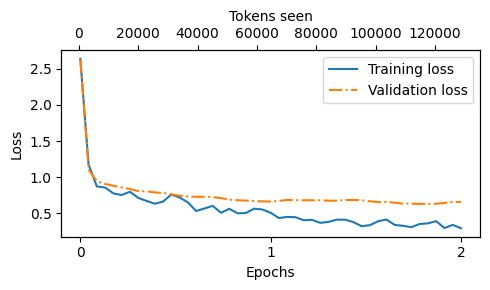

In [ ]:
from previous_chapters import plot_losses
# Alternatively:
# from llms_from_scratch.ch05 import plot_losses

epochs_tensor = torch.linspace(0, num_epochs, len(train_losses))
plot_losses(epochs_tensor, tokens_seen, train_losses, val_losses)

**Pola kurvanya klasik.** Loss turun tajam dalam 10 langkah pertama (validation dari 2.626 ke 0.944), lalu melandai sepanjang epoch pertama sampai train 0.509 dan validation 0.663 di step 115. Di epoch kedua, keduanya berpisah jalan. Loss train terus turun sampai sekitar 0.3. Validation justru naik dulu ke 0.686 di awal epoch, turun perlahan ke titik terendah 0.6306 di step 210, lalu naik lagi ke 0.6561 di step 230. Jadi seluruh epoch kedua hanya memperbaiki validation sekitar 0.03 di titik terbaiknya, sementara train turun sekitar 0.2.

Celah yang melebar itu adalah tanda awal *overfitting*, yaitu ketika model mulai menghafal contoh training lebih cepat daripada belajar hal yang berguna untuk contoh baru. Repo penulis mencatat hal yang sama: overfitting ringan mulai terlihat sekitar epoch pertama. Satu catatan agar tidak terlalu jauh menafsirkan: setiap titik validation hanya rata-rata 5 batch (40 contoh), jadi naik-turun kecil di epoch kedua sebagian besar adalah noise. Figure 7.17 buku tidak ditampilkan, karena gambar yang sama dihasilkan oleh sel di atas.

Angka terakhir di log training mudah disalahpahami sebagai kinerja model akhir. Sebenarnya bukan. `train_model_simple` mengevaluasi setiap 5 langkah, jadi evaluasi terakhirnya terjadi di step 230, sesudah 231 update, sementara training berhenti sesudah 232 update (2 epoch x 116 batch). Evaluasi itu juga hanya memakai 5 batch train dari urutan shuffle saat itu. Sel berikut mengukur model akhir secara terpisah, dengan cakupan yang ditulis eksplisit, tanpa training tambahan.

In [ ]:
# Sel tambahan: pengukuran model akhir sesudah training (terpisah dari evaluasi terakhir di log)
n_logged = len(train_losses)
last_logged_evaluation = {
    "step": 5 * (n_logged - 1), "after_optimizer_updates": 5 * (n_logged - 1) + 1,
    "train_loss": train_losses[-1], "val_loss": val_losses[-1], "tokens_seen": tokens_seen[-1],
    "scope": "evaluate_model(eval_iter=5): 5 batch train (urutan shuffle saat itu) + 5 batch validation pertama"}
optimizer_updates_total = len(train_loader) * num_epochs

torch.manual_seed(123)                 # urutan batch train sama dengan pengukuran loss awal di atas
with torch.no_grad():
    final_model_eval = {
        "after_optimizer_updates": optimizer_updates_total,
        "train_loss_5_batches_seed123": calc_loss_loader(train_loader, model, device, num_batches=5),
        "val_loss_5_batches": calc_loss_loader(val_loader, model, device, num_batches=5),
        "val_loss_full": calc_loss_loader(val_loader, model, device),
        "test_loss_full": calc_loss_loader(test_loader, model, device),
        "scope": {"train_loss_5_batches_seed123": "5 batch train pertama sesudah torch.manual_seed(123), sama dengan loss awal",
                  "val_loss_5_batches": "5 batch validation pertama (40 contoh), sama dengan loss awal",
                  "val_loss_full": f"semua {len(val_loader)} batch validation ({len(val_data)} contoh)",
                  "test_loss_full": f"semua {len(test_loader)} batch test ({len(test_data)} contoh)"}}
print("evaluasi terakhir di log :", json.dumps(last_logged_evaluation, indent=1))
print("total optimizer update   :", optimizer_updates_total)
print("model akhir (terpisah)   :", json.dumps(final_model_eval, indent=1))
print("loss awal (5 batch, seed 123): train", train_loss, "| val", val_loss)

evaluasi terakhir di log : {
 "step": 230,
 "after_optimizer_updates": 231,
 "train_loss": 0.2943525493144989,
 "val_loss": 0.6560537695884705,
 "tokens_seen": 128776,
 "scope": "evaluate_model(eval_iter=5): 5 batch train (urutan shuffle saat itu) + 5 batch validation pertama"
}
total optimizer update   : 232
model akhir (terpisah)   : {
 "after_optimizer_updates": 232,
 "train_loss_5_batches_seed123": 0.3142522692680359,
 "val_loss_5_batches": 0.6550617218017578,
 "val_loss_full": 0.6324559705598014,
 "test_loss_full": 0.683131530880928,
 "scope": {
  "train_loss_5_batches_seed123": "5 batch train pertama sesudah torch.manual_seed(123), sama dengan loss awal",
  "val_loss_5_batches": "5 batch validation pertama (40 contoh), sama dengan loss awal",
  "val_loss_full": "semua 7 batch validation (55 contoh)",
  "test_loss_full": "semua 14 batch test (110 contoh)"
 }
}
loss awal (5 batch, seed 123): train 3.82590913772583 | val 3.7619335651397705


**Pada 5 batch yang persis sama dengan pengukuran sebelum training, loss train turun dari 3.826 ke 0.3143 dan loss validasi dari 3.762 ke 0.6551.** Inilah perbandingan sebelum-sesudah yang paling adil di notebook ini, karena batch dan seed-nya identik.

Pada seluruh validation set (55 contoh), loss model akhir 0.6325. Pada test set (110 contoh yang tidak pernah dipakai untuk memilih apa pun), 0.6831. Test sedikit lebih tinggi (selisih 0.051), dan itu wajar: dua set kecil berisi instruksi yang berbeda-beda tidak akan memberi angka yang persis sama.

Evaluasi terakhir di log (step 230) mencatat train 0.2944, sedangkan pengukuran model akhir mencatat 0.3143. Selisih ini bukan tanda model memburuk di update terakhir. Keduanya mengukur batch yang berbeda: log memakai 5 batch dari urutan shuffle saat itu, sedangkan sel ini memakai 5 batch yang dipilih seed 123. Karena itu, sepanjang notebook angka log dibandingkan dengan log buku, dan angka model akhir dibandingkan dengan loss awal.

In [ ]:
# UTH 2 + 3 (sel tambahan): pengukuran yang sama pada model sesudah fine-tuning
uth2_ft = loss_anatomy(model, val_data, device)
show_anatomy(uth2_ft, "fine-tuned")
print()
print("   segmen               CE pretrained -> fine-tuned")
for s in SEGMENTS:
    print(f"   {s:20s} {uth2_base['seg'][s]['mean']:7.3f} -> {uth2_ft['seg'][s]['mean']:7.3f}")

[fine-tuned]  segmen             token   CE rata2   porsi loss
   preamble               1265     0.000       0.0%
   instruction+input       802     1.534      62.0%
   header                  330     0.018       0.3%
   response                664     1.118      37.4%
   eos                      55     0.114       0.3%
   P(<|endoftext|> | jawaban gold): rata-rata 0.9558, median 0.9998
   generasi greedy 3 prompt test: berhenti sendiri 3/3, token baru [15, 20, 22]

   segmen               CE pretrained -> fine-tuned
   preamble               4.255 ->   0.000
   instruction+input      5.076 ->   1.534
   header                 0.989 ->   0.018
   response               2.780 ->   1.118
   eos                    4.269 ->   0.114


**Prediksinya terbukti, dengan satu kejutan.**

**Teks yang tetap dihafal sepenuhnya.** Cross-entropy kalimat pembuka turun dari 4.255 ke 0.000, dan header `### Response:` dari 0.989 ke 0.018. Model kini memprediksi 23 token pembuka itu dengan keyakinan praktis 100%.

**Isi jawaban turun dari 2.780 ke 1.118, tapi tidak mendekati nol**, karena jawaban memang berbeda-beda dan sebagian benar-benar sulit.

**Kejutannya ada di instruksi.** Cross-entropy teks instruksi plus input juga turun banyak, dari 5.076 ke 1.534, padahal isinya berbeda di setiap contoh. Model ternyata belajar menebak gaya instruksi di dataset ini, dan gaya itu memang sangat seragam. Kalau dihitung dari file dataset, 300 dari 1,100 instruksi diawali kata "What" (235 di antaranya "What is the"), 99 diawali "Convert", dan 96 diawali "Rewrite". Begitu model tahu pola-pola pembuka ini, sebagian besar token instruksi menjadi mudah ditebak. Meski begitu, segmen inilah yang kini menyumbang porsi terbesar sisa loss, 62.0%, sementara isi jawaban 37.4%.

**Token akhir berubah paling drastis.** Peluang berhenti tepat sesudah jawaban yang benar naik dari 0.0169 ke 0.9558, dengan median 0.9998: untuk separuh contoh validasi, model hampir pasti berhenti di tempat yang tepat. Ketiga generasi greedy kini berhenti sendiri, masing-masing sesudah 15, 20, dan 22 token. Satu token 50256 yang sengaja dipertahankan collate function di 7.3 adalah satu-satunya sumber sinyal ini.

**Implikasinya untuk debat masking (Exercise 7.2).** Angka loss yang dilaporkan selama training adalah campuran segmen yang sangat berbeda, dan sesudah fine-tuning sebagian besar campuran itu berasal dari teks instruksi -- justru segmen yang dibuang bila instruksi di-mask. Jadi loss validasi run dengan dan tanpa masking tidak bisa dibandingkan begitu saja. Yang sebanding adalah loss pada segmen jawaban.

**Exercise 7.3** (fine-tuning dengan dataset Alpaca 52k) dibahas di bagian Exercises.

## 7.7 Extracting and saving responses

Loss memberi tahu seberapa yakin model terhadap teks yang benar, tapi tidak memberi tahu jawaban macam apa yang ia tulis sendiri. Tahap ketiga dimulai dengan menjalankan model pada 110 instruksi test yang belum pernah dilihatnya.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/07.Chapter07/figure7.18.png" width="700">

**Figure 7.18** Langkah 7 dan 8: mengekstrak respons test set dan membandingkannya secara kualitatif.

Kita mulai dari tiga contoh pertama, dicetak berdampingan dengan jawaban yang benar. Respons diambil dengan membuang prompt dan header `### Response:` dari teks yang dihasilkan.

In [ ]:
torch.manual_seed(123)


for entry in test_data[:3]:

    input_text = format_input(entry)

    token_ids = generate(
        model=model,
        idx=text_to_token_ids(input_text, tokenizer).to(device),
        max_new_tokens=256,
        context_size=BASE_CONFIG["context_length"],
        eos_id=50256
    )
    generated_text = token_ids_to_text(token_ids, tokenizer)
    response_text = (
        generated_text[len(input_text):]
        .replace("### Response:", "")
        .strip()
)

    print(input_text)
    print(f"\nCorrect response:\n>> {entry['output']}")
    print(f"\nModel response:\n>> {response_text.strip()}")
    print("-------------------------------------")

Below is an instruction that describes a task. Write a response that appropriately completes the request.

### Instruction:
Rewrite the sentence using a simile.

### Input:
The car is very fast.

Correct response:
>> The car is as fast as lightning.

Model response:
>> The car is as fast as a bullet.
-------------------------------------
Below is an instruction that describes a task. Write a response that appropriately completes the request.

### Instruction:
What type of cloud is typically associated with thunderstorms?

Correct response:
>> The type of cloud typically associated with thunderstorms is cumulonimbus.

Model response:
>> The type of cloud associated with thunderstorms is a cumulus cloud.
-------------------------------------
Below is an instruction that describes a task. Write a response that appropriately completes the request.

### Instruction:
Name the author of 'Pride and Prejudice'.

Correct response:
>> Jane Austen.

Model response:
>> The author of 'Pride and Prej

**Ketiga jawaban identik kata demi kata dengan contoh di buku.** Contoh pertama benar dengan pilihan kata sendiri: "as fast as a bullet" untuk jawaban acuan "as fast as lightning". Contoh ketiga juga benar, hanya lebih panjang dari acuannya. Contoh kedua yang menarik. Model menjawab "a cumulus cloud", padahal acuannya cumulonimbus. Jawabannya terdengar sangat meyakinkan dan hampir benar -- cumulus memang bisa tumbuh menjadi cumulonimbus -- tapi tetap salah.

Contoh kedua itu menunjukkan kenapa evaluasi di bab ini tidak bisa sesederhana menghitung akurasi seperti di Chapter 6. Jawaban bisa benar dengan kata yang berbeda, dan jawaban bisa salah dengan kalimat yang hampir sama dengan acuan.

Dalam praktiknya, model instruksi dievaluasi dengan tiga keluarga metode. Ada benchmark pilihan ganda atau jawaban singkat seperti MMLU ([arXiv:2009.03300](https://arxiv.org/abs/2009.03300)) yang menguji pengetahuan. Ada perbandingan preferensi manusia antar model, seperti LMSYS Chatbot Arena. Dan ada benchmark percakapan otomatis yang memakai LLM lain sebagai juri, seperti AlpacaEval. Karena bab ini peduli pada kemampuan percakapan -- jawaban yang relevan, koheren, dan sesuai instruksi -- dua keluarga terakhir lebih cocok. Menilai ratusan jawaban dengan tangan terlalu mahal, jadi buku memilih jalan AlpacaEval: LLM yang lebih besar menilai setiap jawaban terhadap acuan di test set kita sendiri.

Langkah pertamanya adalah mengumpulkan respons untuk seluruh test set (listing 7.9) dan menyimpannya ke JSON.

In [ ]:
# Sel tambahan: catat waktu mulai listing 7.9 (untuk ringkasan run)
TIMERS["generate_start"] = time.time()

In [ ]:
from tqdm import tqdm

for i, entry in tqdm(enumerate(test_data), total=len(test_data)):

    input_text = format_input(entry)

    token_ids = generate(
        model=model,
        idx=text_to_token_ids(input_text, tokenizer).to(device),
        max_new_tokens=256,
        context_size=BASE_CONFIG["context_length"],
        eos_id=50256
    )
    generated_text = token_ids_to_text(token_ids, tokenizer)
    response_text = generated_text[len(input_text):].replace("### Response:", "").strip()

    test_data[i]["model_response"] = response_text


with open("instruction-data-with-response.json", "w") as file:
    json.dump(test_data, file, indent=4)  # "indent" for pretty-printing

100%|██████████| 110/110 [01:17<00:00,  1.42it/s]


110 respons dihasilkan dalam 01:17 (1.42 it/s) di T4, sebanding dengan output tersimpan sel yang sama di repo penulis (1:11 untuk snapshot era terbit, 1:08 untuk HEAD). Fungsi `generate` dari Chapter 5 tidak memakai *KV cache*, yaitu trik menyimpan hasil perhitungan attention untuk token-token sebelumnya. Akibatnya, setiap token baru menjalankan ulang forward pass penuh atas seluruh konteks, sehingga jawaban yang panjang jauh lebih mahal daripada jawaban pendek.

In [ ]:
# Sel tambahan: catat waktu selesai listing 7.9 (untuk ringkasan run; tanpa output)
TIMERS["generate_end"] = time.time()

In [ ]:
# UTH 3 (lanjutan, sel tambahan): apakah generasi test set berhenti sendiri sebelum batas 256 token?
resp_tokens = [len(tokenizer.encode(e["model_response"])) for e in test_data]
header = len(tokenizer.encode("\n\n### Response:\n"))
print(f"token respons (setelah header dibuang): min {min(resp_tokens)}, median {statistics.median(resp_tokens)}, "
      f"maks {max(resp_tokens)}")
print(f"respons + header terpanjang: {max(resp_tokens) + header} token baru dari batas 256")
print(f"respons kosong: {sum(t == 0 for t in resp_tokens)}")

token respons (setelah header dibuang): min 1, median 11.0, maks 250
respons + header terpanjang: 256 token baru dari batas 256
respons kosong: 0


**109 dari 110 jawaban berhenti sendiri; satu tidak.** Kebanyakan jawaban pendek: median 11 token, terpendek 1 token. Tapi jawaban terpanjang mencapai 250 token. Kalau ditambah 6 token header `### Response:`, totalnya tepat 256, yaitu batas `max_new_tokens`. Dengan kata lain, untuk satu instruksi model tidak pernah memilih untuk berhenti; generasinya dipotong.

Instruksinya: *"What is the formula for calculating work done?"* (indeks 87 di test set). Jawabannya dibuka dengan kalimat yang tepat, "The formula for calculating work done is W =", lalu langsung keluar jalur: `(1 - H) + (1 - C) + (1 - D) + (1 - E) + ...`, terus menyusuri alfabet sampai jatahnya habis. Jawaban yang benar sebenarnya sederhana, gaya dikali jarak. Ini contoh klasik *repetition loop* pada decoding greedy: setiap kali pola `+ (1 - X)` muncul, pola yang sama menjadi pilihan paling mungkin berikutnya, dan model tidak punya cara keluar.

Run penulis yang tersimpan di repo juga punya tepat satu kasus seperti ini, tapi pada instruksi lain (*"Sort the following list in descending order."*). Jadi ini bukan keanehan run kita, melainkan sifat model kecil dengan decoding greedy. UTH 3 menunjukkan model sudah belajar kapan berhenti dalam hampir semua kasus, tapi `max_new_tokens` tetap dibutuhkan sebagai jaring pengaman.

In [ ]:
print(test_data[0])

{'instruction': 'Rewrite the sentence using a simile.', 'input': 'The car is very fast.', 'output': 'The car is as fast as lightning.', 'model_response': 'The car is as fast as a bullet.'}


Entri pertama test set kini punya kunci keempat, `model_response`, berisi jawaban yang sama dengan yang tercetak di atas. Seluruh test set beserta jawabannya tersimpan di `instruction-data-with-response.json`, sehingga evaluasi bisa dijalankan di sesi terpisah tanpa memuat GPT-2 lagi.

**Seberapa mirip jawaban kita dengan jawaban run penulis?** File respons yang disimpan penulis di repo memungkinkan perbandingan langsung: 68 dari 110 jawaban identik kata demi kata, dan 42 berbeda. Data, seed, dan bobot awalnya sama, jadi perbedaan itu berasal dari pembulatan float yang menumpuk selama training. Begitu satu pilihan token greedy berbeda, sisa jawabannya ikut bercabang. Hanya 16 jawaban yang sama persis dengan acuan dataset, sebuah pengingat bahwa kecocokan harfiah adalah ukuran yang terlalu kasar untuk model instruksi.

In [ ]:
import re


file_name = f"{re.sub(r'[ ()]', '', CHOOSE_MODEL) }-sft.pth"
torch.save(model.state_dict(), file_name)
print(f"Model saved as {file_name}")

# Load model via
# model.load_state_dict(torch.load("gpt2-medium355M-sft.pth"))

Model saved as gpt2-medium355M-sft.pth


Bobot hasil fine-tuning disimpan sebagai `gpt2-medium355M-sft.pth` di disk runtime Colab. Ukuran filenya tidak dicetak run ini. Ledger di 7.5 memperkirakan 1.63 GB, tapi seperti pada checkpoint, angka itu belum menghitung 24 buffer causal mask yang ikut tersimpan di state dict, sehingga ukuran sebenarnya kira-kira 1.73 GB. File itu tidak ikut disertakan bersama notebook; untuk memakainya, cukup jalankan ulang notebook ini atau muat dengan `model.load_state_dict(torch.load("gpt2-medium355M-sft.pth"))`.

## 7.8 Evaluating the fine-tuned LLM

Tiga jawaban bisa dinilai dengan mata; 110 tidak. Langkah terakhir pipeline mengotomasi penilaian dengan LLM lain yang lebih besar.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/07.Chapter07/figure7.19.png" width="700">

**Figure 7.19** Langkah 9: memberi skor respons test set dengan LLM lain sebagai juri.

Juri pilihan buku adalah Llama 3 8B versi instruct, dijalankan lokal lewat [Ollama](https://ollama.com). Ollama adalah aplikasi untuk menjalankan LLM secara efisien di laptop; ia membungkus llama.cpp dan hanya dipakai untuk inferensi, bukan training. Ollama harus berjalan di latar belakang, baik lewat `ollama serve` di terminal maupun lewat aplikasinya di macOS, dan modelnya diunduh sekali dengan `ollama run llama3` (4.7 GB).

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/07.Chapter07/figure7.20.png" width="700">

**Figure 7.20** Dua cara menjalankan Ollama: ollama serve di terminal, atau aplikasi Ollama di latar belakang macOS.

Di sinilah run Colab kita berhenti menghasilkan angka. Colab tidak menjalankan Ollama, jadi kelima sel buku berikut dijalankan lewat harness. Hasilnya adalah error yang tercatat, bukan skor. Di mesin yang menjalankan Ollama dengan `llama3`, sel-sel yang sama akan memberi skor buku sungguhan. Notebook ini sengaja tidak mengganti juri secara diam-diam, karena skor dari juri lain bukan angka yang sama dengan skor buku.

In [ ]:
# Sel buku (harness): cek proses Ollama. Tanpa Ollama, kode buku sendiri melempar RuntimeError.
CEK_OLLAMA = r'''
import psutil

def check_if_running(process_name):
    running = False
    for proc in psutil.process_iter(["name"]):
        if process_name in proc.info["name"]:
            running = True
            break
    return running

ollama_running = check_if_running("ollama")

if not ollama_running:
    raise RuntimeError("Ollama not running. Launch ollama before proceeding.")
print("Ollama running:", check_if_running("ollama"))
'''
run_listing('Cek Ollama (listing buku)', CEK_OLLAMA)


[harness] Cek Ollama (listing buku): RuntimeError -- traceback riil di atas; Run all berlanjut.


Traceback (most recent call last):
  File "/tmp/ipykernel_2355/3280993272.py", line 31, in run_listing
    exec(compile(src, fname, "exec"), globals())
    ~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "<Cek Ollama (listing buku)>", line 14, in <module>
    raise RuntimeError("Ollama not running. Launch ollama before proceeding.")
RuntimeError: Ollama not running. Launch ollama before proceeding.


Sesuai dugaan, kode buku sendiri berhenti dengan `RuntimeError: Ollama not running`. Pemeriksaan ini hanya mencari proses yang namanya mengandung "ollama" lewat `psutil`; ia tidak tahu model apa yang terpasang.

In [ ]:
# This cell is optional; it allows you to restart the notebook
# and only run section 7.7 without rerunning any of the previous code
import json
from tqdm import tqdm

file_path = "instruction-data-with-response.json"

with open(file_path, "r") as file:
    test_data = json.load(file)


def format_input(entry):
    instruction_text = (
        f"Below is an instruction that describes a task. "
        f"Write a response that appropriately completes the request."
        f"\n\n### Instruction:\n{entry['instruction']}"
    )

    input_text = f"\n\n### Input:\n{entry['input']}" if entry["input"] else ""

    return instruction_text + input_text

Sel opsional di atas memuat ulang file respons dan mendefinisikan ulang `format_input`, supaya bagian 7.8 bisa dijalankan di sesi Python baru tanpa memuat GPT-2.

Listing 7.10 berbicara dengan Ollama lewat REST API: kirim nama model dan pesan pengguna, dengan opsi `seed=123`, `temperature=0`, dan `num_ctx=2048` agar jawabannya sedeterministik mungkin, lalu rangkai potongan jawaban yang datang sebagai stream.

In [ ]:
# Sel buku (harness): listing 7.10 query_model + contoh, juri llama3 via Ollama REST API.
LISTING_7_10 = r'''
import requests  # noqa: F811
# import urllib.request

def query_model(
    prompt,
    model="llama3",
    # If you used OLLAMA_HOST=127.0.0.1:11435 ollama serve
    # update the address from 11434 to 11435
    url="http://localhost:11434/api/chat"
):
    # Create the data payload as a dictionary
    data = {
        "model": model,
        "messages": [
            {"role": "user", "content": prompt}
        ],
        "options": {     # Settings below are required for deterministic responses
            "seed": 123,
            "temperature": 0,
            "num_ctx": 2048
        }
    }


    """
    # Convert the dictionary to a JSON formatted string and encode it to bytes
    payload = json.dumps(data).encode("utf-8")

    # Create a request object, setting the method to POST and adding necessary headers
    request = urllib.request.Request(
        url,
        data=payload,
        method="POST"
    )
    request.add_header("Content-Type", "application/json")

    # Send the request and capture the response
    response_data = ""
    with urllib.request.urlopen(request) as response:
        # Read and decode the response
        while True:
            line = response.readline().decode("utf-8")
            if not line:
                break
            response_json = json.loads(line)
            response_data += response_json["message"]["content"]

    return response_data
    """

    # The book originally used the commented-out code above, which is based
    # on urllib. It works generally fine, but some readers reported
    # issues with using urllib when using a (company) VPN.
    # The code below uses the requests library, which doesn't seem
    # to have these issues.

    # Send the POST request
    with requests.post(url, json=data, stream=True, timeout=30) as r:
        r.raise_for_status()
        response_data = ""
        for line in r.iter_lines(decode_unicode=True):
            if not line:
                continue
            response_json = json.loads(line)
            if "message" in response_json:
                response_data += response_json["message"]["content"]

    return response_data


model = "llama3"
result = query_model("What do Llamas eat?", model)
print(result)
'''
run_listing('Listing 7.10 (juri llama3)', LISTING_7_10)


[harness] Listing 7.10 (juri llama3): ConnectionError -- traceback riil di atas; Run all berlanjut.


Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/urllib3/connection.py", line 198, in _new_conn
    sock = connection.create_connection(
        (self._dns_host, self.port),
    ...<2 lines>...
        socket_options=self.socket_options,
    )
  File "/usr/local/lib/python3.13/dist-packages/urllib3/util/connection.py", line 85, in create_connection
    raise err
  File "/usr/local/lib/python3.13/dist-packages/urllib3/util/connection.py", line 73, in create_connection
    sock.connect(sa)
    ~~~~~~~~~~~~^^^^
ConnectionRefusedError: [Errno 111] Connection refused

The above exception was the direct cause of the following exception:

Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/urllib3/connectionpool.py", line 787, in urlopen
    response = self._make_request(
        conn,
    ...<10 lines>...
        **response_kw,
    )
  File "/usr/local/lib/python3.13/dist-packages/urllib3/connectionpool.py", line 493, in _make_

Fungsi `query_model` terdefinisi, tapi panggilan contohnya gagal dengan `ConnectionError` (connection refused): tidak ada server Ollama di `localhost:11434` pada runtime Colab.

In [ ]:
# Sel buku (harness): penilaian verbose 3 contoh pertama oleh juri llama3.
SKOR_VERBOSE_3 = r'''
for entry in test_data[:3]:
    prompt = (
        f"Given the input `{format_input(entry)}` "
        f"and correct output `{entry['output']}`, "
        f"score the model response `{entry['model_response']}`"
        f" on a scale from 0 to 100, where 100 is the best score. "
    )
    print("\nDataset response:")
    print(">>", entry['output'])
    print("\nModel response:")
    print(">>", entry["model_response"])
    print("\nScore:")
    print(">>", query_model(prompt))
    print("\n-------------------------")
'''
run_listing('Skor verbose 3 contoh (juri llama3)', SKOR_VERBOSE_3)


Dataset response:
>> The car is as fast as lightning.

Model response:
>> The car is as fast as a bullet.

Score:

[harness] Skor verbose 3 contoh (juri llama3): ConnectionError -- traceback riil di atas; Run all berlanjut.


Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/urllib3/connection.py", line 198, in _new_conn
    sock = connection.create_connection(
        (self._dns_host, self.port),
    ...<2 lines>...
        socket_options=self.socket_options,
    )
  File "/usr/local/lib/python3.13/dist-packages/urllib3/util/connection.py", line 85, in create_connection
    raise err
  File "/usr/local/lib/python3.13/dist-packages/urllib3/util/connection.py", line 73, in create_connection
    sock.connect(sa)
    ~~~~~~~~~~~~^^^^
ConnectionRefusedError: [Errno 111] Connection refused

The above exception was the direct cause of the following exception:

Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/urllib3/connectionpool.py", line 787, in urlopen
    response = self._make_request(
        conn,
    ...<10 lines>...
        **response_kw,
    )
  File "/usr/local/lib/python3.13/dist-packages/urllib3/connectionpool.py", line 493, in _make_

Penilaian verbose untuk tiga contoh pertama gagal dengan cara yang sama. Sebagai acuan saja -- **ini angka run penulis yang tersimpan di repo, bukan hasil run ini** -- juri Llama 3 di mesin penulis memberi 85 untuk "as fast as a bullet", 40 untuk "cumulus cloud" (juri mengenali bahwa jawaban yang benar adalah cumulonimbus dan memberi nilai sebagian), dan 95 untuk jawaban Jane Austen.

In [ ]:
# Sel buku (harness): listing 7.11 skor integer 110 respons oleh juri llama3.
LISTING_7_11 = r'''
def generate_model_scores(json_data, json_key, model="llama3"):
    scores = []
    for entry in tqdm(json_data, desc="Scoring entries"):
        prompt = (
            f"Given the input `{format_input(entry)}` "
            f"and correct output `{entry['output']}`, "
            f"score the model response `{entry[json_key]}`"
            f" on a scale from 0 to 100, where 100 is the best score. "
            f"Respond with the integer number only."
        )
        score = query_model(prompt, model)
        try:
            scores.append(int(score))
        except ValueError:
            print(f"Could not convert score: {score}")
            continue

    return scores


scores = generate_model_scores(test_data, "model_response")
print(f"Number of scores: {len(scores)} of {len(test_data)}")
print(f"Average score: {sum(scores)/len(scores):.2f}\n")
'''
run_listing('Listing 7.11 (skor integer, juri llama3)', LISTING_7_11)

Scoring entries:   0%|          | 0/110 [00:00<?, ?it/s]


[harness] Listing 7.11 (skor integer, juri llama3): ConnectionError -- traceback riil di atas; Run all berlanjut.



Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/urllib3/connection.py", line 198, in _new_conn
    sock = connection.create_connection(
        (self._dns_host, self.port),
    ...<2 lines>...
        socket_options=self.socket_options,
    )
  File "/usr/local/lib/python3.13/dist-packages/urllib3/util/connection.py", line 85, in create_connection
    raise err
  File "/usr/local/lib/python3.13/dist-packages/urllib3/util/connection.py", line 73, in create_connection
    sock.connect(sa)
    ~~~~~~~~~~~~^^^^
ConnectionRefusedError: [Errno 111] Connection refused

The above exception was the direct cause of the following exception:

Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/urllib3/connectionpool.py", line 787, in urlopen
    response = self._make_request(
        conn,
    ...<10 lines>...
        **response_kw,
    )
  File "/usr/local/lib/python3.13/dist-packages/urllib3/connectionpool.py", line 493, in _make

**Tidak ada skor juri di notebook ini.** Listing 7.11 gagal sejak entri pertama karena alasan yang sama. Sebagai acuan, output tersimpan repo penulis mencatat 110 dari 110 skor dengan rata-rata 50.32 (snapshot era terbit) dan 49.45 (HEAD), dan README repo mencatat 51.75 untuk skrip standalone. Sebagai pembanding, notebook yang sama menyebut Llama 3 8B base mendapat 58.51 dan Llama 3 8B instruct 82.65. Semua angka itu milik penulis. Menempelkannya di sini sebagai hasil run kita akan menyesatkan, apalagi 42 jawaban kita berbeda dari jawaban run penulis.

Untuk mendapat skor buku, jalankan bagian 7.8 di mesin dengan Ollama dan `llama3` terpasang, memakai `instruction-data-with-response.json` dari run ini.

### Eksperimen alternatif (opsional, bukan juri buku)

Notebook ini menyiapkan jalur kedua untuk mesin yang punya Ollama tapi bukan `llama3`. Bila `RUN_ALT_JUDGE = True` dan model `ALT_JUDGE_MODEL` tersedia, prompt buku yang sama dipakai untuk juri lain. Respons mentah, digest model, seed, dan temperature dicatat, dan payload ditambah `"think": False`. Tambahan itu satu-satunya perubahan, dan diperlukan karena model dengan mode berpikir bawaan tidak memberi skor tanpanya: saat builder mencoba `qwen3.5:9b` tanpa opsi itu, model menghabiskan 1,936 token untuk berpikir sampai batas panjangnya tercapai, dan isi jawabannya kosong. Skor dari juri lain tidak bisa disandingkan dengan angka Llama 3 buku. Di run ini jalur alternatif mati.

In [ ]:
# Eksperimen alternatif (sel tambahan): guard -- jalan hanya bila diminta DAN Ollama + model tersedia
import requests


def ollama_models():
    try:
        return {m["name"]: m for m in requests.get("http://localhost:11434/api/tags", timeout=5).json()["models"]}
    except Exception:
        return None


_models = ollama_models() if RUN_ALT_JUDGE else None
ALT_JUDGE_OK = bool(RUN_ALT_JUDGE and _models and ALT_JUDGE_MODEL in _models)
ALT_JUDGE_REASON = ("aktif" if ALT_JUDGE_OK else "RUN_ALT_JUDGE = False" if not RUN_ALT_JUDGE else
                    "Ollama tidak terjangkau di localhost:11434" if _models is None else
                    f"model {ALT_JUDGE_MODEL} tidak terpasang di Ollama")
JUDGE_OPTIONS = {"seed": 123, "temperature": 0, "num_ctx": 2048}     # sama dengan listing 7.10
judge_meta = None
if ALT_JUDGE_OK:
    show = requests.post("http://localhost:11434/api/show", json={"model": ALT_JUDGE_MODEL}, timeout=10).json()
    judge_meta = {"ollama_version": requests.get("http://localhost:11434/api/version", timeout=5).json()["version"],
                  "model": ALT_JUDGE_MODEL, "digest": _models[ALT_JUDGE_MODEL]["digest"],
                  "details": _models[ALT_JUDGE_MODEL].get("details"), "capabilities": show.get("capabilities"),
                  "modelfile_parameters": show.get("parameters"), "options": JUDGE_OPTIONS, "think": False}
    print(json.dumps(judge_meta, indent=1))
else:
    print("eksperimen juri alternatif dilewati:", ALT_JUDGE_REASON)


def query_model_alt(prompt, model=ALT_JUDGE_MODEL, url="http://localhost:11434/api/chat"):
    data = {"model": model, "messages": [{"role": "user", "content": prompt}],
            "options": dict(JUDGE_OPTIONS), "think": False}
    with requests.post(url, json=data, stream=True, timeout=120) as r:
        r.raise_for_status()
        response_data, last = "", {}
        for line in r.iter_lines(decode_unicode=True):
            if line:
                last = json.loads(line)
                if "message" in last:
                    response_data += last["message"]["content"]
    return response_data, {k: last.get(k) for k in ("model", "done_reason", "eval_count", "prompt_eval_count")}


def generate_model_scores_alt(json_data, json_key, raw_log):
    scores = []
    for entry in tqdm(json_data, desc="Scoring entries"):
        prompt = (
            f"Given the input `{format_input(entry)}` "
            f"and correct output `{entry['output']}`, "
            f"score the model response `{entry[json_key]}`"
            f" on a scale from 0 to 100, where 100 is the best score. "
            f"Respond with the integer number only."
        )
        score, info = query_model_alt(prompt)
        raw_log.append({"instruction": entry["instruction"], "key": json_key, "response_scored": entry[json_key],
                        "raw": score, **info})
        try:
            scores.append(int(score))
        except ValueError:
            print(f"Could not convert score: {score}")
            continue
    return scores

eksperimen juri alternatif dilewati: RUN_ALT_JUDGE = False


Dilewati, karena `RUN_ALT_JUDGE = False`. Fungsi-fungsinya tetap terdefinisi, siap dipakai bila flag dinyalakan di mesin dengan Ollama.

In [ ]:
# Eksperimen alternatif (sel tambahan, guard): skor 110 respons + kalibrasi plafon/lantai/skor ulang (UTH 4)
alt_judge = None
if ALT_JUDGE_OK:
    raw = {"model": [], "gold": [], "echo": [], "repeat": []}
    calib = [dict(e, gold_as_response=e["output"], echo_as_response=e["instruction"]) for e in test_data]
    s_model = generate_model_scores_alt(test_data, "model_response", raw["model"])
    s_gold = generate_model_scores_alt(calib, "gold_as_response", raw["gold"])
    s_echo = generate_model_scores_alt(calib, "echo_as_response", raw["echo"])
    s_rep = generate_model_scores_alt(test_data, "model_response", raw["repeat"])
    same = sum(a["raw"] == b["raw"] for a, b in zip(raw["model"], raw["repeat"]))
    alt_judge = {"meta": judge_meta, "raw": raw,
                 "summary": {k: {"n": len(v), "mean": sum(v) / len(v) if v else None}
                             for k, v in [("model", s_model), ("gold", s_gold), ("echo", s_echo), ("repeat", s_rep)]},
                 "repeat_identical": same}
    with open("judge-raw-alt.json", "w") as f:
        json.dump(alt_judge, f, indent=1)
    for k, v in alt_judge["summary"].items():
        print(f"{k:7s}: {v['n']} skor, rata-rata {v['mean']}")
    print(f"skor ulang identik: {same}/{len(raw['model'])}")
else:
    print("dilewati (eksperimen juri alternatif tidak aktif)")

dilewati (eksperimen juri alternatif tidak aktif)


Dilewati juga. Kalibrasi juri yang direncanakan sebagai UTH 4 tidak menghasilkan angka di run ini. Kalibrasi itu mengukur skor untuk jawaban acuan (plafon), untuk jawaban yang hanya mengulang instruksi (lantai), dan stabilitas skor saat penilaian diulang.

## 7.9 Conclusions

Bab ini menutup siklus pengembangan LLM di buku: arsitektur (Chapter 2-4), pretraining dan pemuatan bobot (Chapter 5), lalu dua jalur fine-tuning (Chapter 6 dan 7).

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/07.Chapter07/figure7.21.png" width="700">

**Figure 7.21** Tiga stage pembangunan LLM, lengkap.

Langkah yang sering menyusul instruction fine-tuning adalah *preference fine-tuning*, misalnya dengan DPO (Direct Preference Optimization), untuk menyelaraskan model dengan preferensi pengguna. Buku tidak membahasnya di bab utama; implementasinya dari nol ada di folder `ch07/04_preference-tuning-with-dpo` repo yang sama. Untuk aplikasi nyata dengan model yang lebih besar, penulis merekomendasikan framework seperti LitGPT atau Axolotl alih-alih kode edukasi ini. **Exercise 7.4** (LoRA) dibahas di bawah.

## Exercises

Keempat latihan bab ini meminta training ulang dengan variasi tertentu. Di run ini training ulangnya tidak dijalankan (`RUN_EXERCISES = False`), tapi bagian-bagian yang murah tetap dieksekusi: format prompt Phi-3, mekanisme masking, statistik dataset Alpaca, dan jumlah parameter LoRA. Semuanya memakai definisi resmi dari `exercise_experiments.py`, yang pertama-tama diimpor persis seperti yang disarankan solusi resmi.

In [ ]:
# Errata #4 (harness, sel tambahan): impor yang disarankan exercise-solutions.ipynb untuk Exercise 7.4
IMPOR_EXERCISE_EXPERIMENTS = r'''
from exercise_experiments import LoRALayer, LinearWithLoRA, replace_linear_with_lora
'''
run_listing('Impor exercise_experiments', IMPOR_EXERCISE_EXPERIMENTS)

[harness] Impor exercise_experiments: selesai tanpa error di environment ini.


Impor lolos di Colab. `exercise_experiments.py` meng-import `gpt_download`, yang butuh TensorFlow, dan TensorFlow terpasang di runtime ini. Di venv builder tanpa TensorFlow, impor yang sama gagal dengan `ModuleNotFoundError`. Supaya notebook tetap jalan di keduanya, definisi yang dibutuhkan diambil apa adanya dari file yang sama lewat AST, tanpa ikut menjalankan import TensorFlow di kepala modul.

In [ ]:
# Koreksi Errata #4 (sel tambahan): definisi verbatim dari exercise_experiments.py (repo resmi)
import math
from torch.utils.data import Dataset

def format_input_phi(entry):
    instruction_text = (
        f"<|user|>\n{entry['instruction']}"
    )

    input_text = f"\n{entry['input']}" if entry["input"] else ""

    return instruction_text + input_text


class InstructionDatasetPhi(Dataset):
    def __init__(self, data, tokenizer):
        self.data = data

        # Pre-tokenize texts
        self.encoded_texts = []
        for entry in data:

            ###################################################################
            # NEW: Use `format_input_phi` and adjust the response text template
            instruction_plus_input = format_input_phi(entry)
            response_text = f"\n<|assistant|>:\n{entry['output']}"
            ###################################################################
            full_text = instruction_plus_input + response_text
            self.encoded_texts.append(
                tokenizer.encode(full_text)
            )

    def __getitem__(self, index):
        return self.encoded_texts[index]

    def __len__(self):
        return len(self.data)


class InstructionDatasetWithMasking(Dataset):
    def __init__(self, data, tokenizer):
        self.data = data

        # New: Separate list for instruction lengths
        self.instruction_lengths = []
        self.encoded_texts = []

        for entry in data:
            instruction_plus_input = format_input(entry)
            response_text = f"\n\n### Response:\n{entry['output']}"
            full_text = instruction_plus_input + response_text

            self.encoded_texts.append(
                tokenizer.encode(full_text)
            )

            # New: collect instruction lengths
            instruction_length = len(tokenizer.encode(instruction_plus_input))
            self.instruction_lengths.append(instruction_length)

    def __getitem__(self, index):
        # New: return both instruction lengths and texts separately
        return self.instruction_lengths[index], self.encoded_texts[index]

    def __len__(self):
        return len(self.data)


def custom_collate_with_masking_fn(
    batch,
    pad_token_id=50256,
    ignore_index=-100,
    allowed_max_length=None,
    device="cpu"
):
    # Find the longest sequence in the batch
    batch_max_length = max(len(item)+1 for instruction_length, item in batch)   # New: batch is now a tuple

    # Pad and prepare inputs and targets
    inputs_lst, targets_lst = [], []

    for instruction_length, item in batch:  # New: batch is now a tuple
        new_item = item.copy()
        # Add an <|endoftext|> token
        new_item += [pad_token_id]
        # Pad sequences to max_length
        padded = new_item + [pad_token_id] * (batch_max_length - len(new_item))
        inputs = torch.tensor(padded[:-1])  # Truncate the last token for inputs
        targets = torch.tensor(padded[1:])  # Shift +1 to the right for targets

        # Replace all but the first padding tokens in targets by ignore_index
        mask = targets == pad_token_id
        indices = torch.nonzero(mask).squeeze()
        if indices.numel() > 1:
            targets[indices[1:]] = ignore_index

        # New: Mask all input and instruction tokens in the targets
        targets[:instruction_length-1] = -100

        # Optionally truncate to maximum sequence length
        if allowed_max_length is not None:
            inputs = inputs[:allowed_max_length]
            targets = targets[:allowed_max_length]

        inputs_lst.append(inputs)
        targets_lst.append(targets)

    # Convert list of inputs and targets to tensors and transfer to target device
    inputs_tensor = torch.stack(inputs_lst).to(device)
    targets_tensor = torch.stack(targets_lst).to(device)

    return inputs_tensor, targets_tensor


class LoRALayer(torch.nn.Module):
    def __init__(self, in_dim, out_dim, rank, alpha):
        super().__init__()
        self.A = torch.nn.Parameter(torch.empty(in_dim, rank))
        torch.nn.init.kaiming_uniform_(self.A, a=math.sqrt(5))  # similar to standard weight initialization
        self.B = torch.nn.Parameter(torch.zeros(rank, out_dim))
        self.alpha = alpha
        self.rank = rank

    def forward(self, x):
        # Book formula:      alpha_book * (x @ A @ B)
        # Canonical formula: (alpha_canonical / rank) * (x @ A @ B)
        # For the same rank and matrices, they are equal when alpha_canonical = alpha_book * rank.
        # Here, alpha_book=16 and rank=16 give alpha_canonical=256, so 256 / 16 = 16.
        x = (self.alpha / self.rank) * (x @ self.A @ self.B)
        return x


class LinearWithLoRA(torch.nn.Module):
    def __init__(self, linear, rank, alpha):
        super().__init__()
        self.linear = linear
        self.lora = LoRALayer(
            linear.in_features, linear.out_features, rank, alpha
        )

    def forward(self, x):
        return self.linear(x) + self.lora(x)


def replace_linear_with_lora(model, rank, alpha):
    for name, module in model.named_children():
        if isinstance(module, torch.nn.Linear):
            # Replace the Linear layer with LinearWithLoRA
            setattr(model, name, LinearWithLoRA(module, rank, alpha))
        else:
            # Recursively apply the same function to child modules
            replace_linear_with_lora(module, rank, alpha)

Sel berikut adalah *runner* untuk tiga latihan yang perlu training ulang. Isinya `exercise_experiments.main()` resmi, dengan urutan seed, hyperparameter, dan alur yang sama. Ada dua perbedaan: bobot dimuat lewat jalur safetensors dengan materialisasi seperti di 7.5, dan device mengikuti sel knob. Di run ini runner hanya didefinisikan, tidak dipanggil.

In [ ]:
# Sel tambahan: runner Exercise 7.1 / 7.2 / 7.4 -- versi TF-free dari exercise_experiments.main() (repo resmi).
# Urutan seed, hyperparameter, dan alur identik dengan main(); perbedaannya hanya pemuatan bobot (safetensors HF +
# materialisasi independen, seperti 7.5) dan device mengikuti sel knob notebook.
import re
import time
from functools import partial

from safetensors.torch import load_file
from torch.utils.data import DataLoader
from tqdm import tqdm

from previous_chapters import calc_loss_loader, generate, text_to_token_ids, token_ids_to_text


def run_exercise_variant(variant, data, device, weights_file="model-gpt2-medium.safetensors"):
    assert variant in {"baseline", "phi3_prompt", "mask_instructions", "lora"}
    phi3_prompt, mask_instructions, lora = (variant == "phi3_prompt", variant == "mask_instructions",
                                            variant == "lora")
    train_portion = int(len(data) * 0.85)
    test_portion = int(len(data) * 0.1)
    train_data = data[:train_portion]
    test_data = [dict(e) for e in data[train_portion:train_portion + test_portion]]
    val_data = data[train_portion + test_portion:]

    if mask_instructions:
        collate = partial(custom_collate_with_masking_fn, device=device, allowed_max_length=1024)
        CustomDataset = InstructionDatasetWithMasking
    elif phi3_prompt:
        collate = partial(custom_collate_fn, device=device, allowed_max_length=1024)
        CustomDataset = InstructionDatasetPhi
    else:
        collate = partial(custom_collate_fn, device=device, allowed_max_length=1024)
        CustomDataset = InstructionDataset

    torch.manual_seed(123)
    train_loader = DataLoader(CustomDataset(train_data, tokenizer), batch_size=8, collate_fn=collate,
                              shuffle=True, drop_last=True, num_workers=0)
    val_loader = DataLoader(CustomDataset(val_data, tokenizer), batch_size=8, collate_fn=collate,
                            shuffle=False, drop_last=False, num_workers=0)

    model_hf = GPTModel(BASE_CONFIG)                       # mapping resmi HF (7.5) ...
    load_weights_into_gpt(model_hf, load_file(weights_file))
    model = GPTModel(BASE_CONFIG)                          # ... lalu parameter independen (salinan)
    model.load_state_dict(model_hf.state_dict())
    del model_hf
    model.eval()
    model.to(device)
    print("Loaded model:", CHOOSE_MODEL)
    print(50 * "-")

    if lora:
        total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
        print(f"Total trainable parameters before: {total_params:,}")
        for param in model.parameters():
            param.requires_grad = False
        total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
        print(f"Total trainable parameters after: {total_params:,}")
        replace_linear_with_lora(model, rank=16, alpha=256)    # alpha / rank = 16, skala buku
        total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
        print(f"Total trainable LoRA parameters: {total_params:,}")
        model.to(device)

    print("Initial losses")
    with torch.no_grad():
        train_loss = calc_loss_loader(train_loader, model, device, num_batches=5)
        val_loss = calc_loss_loader(val_loader, model, device, num_batches=5)
    print("   Training loss:", train_loss)
    print("   Validation loss:", val_loss)

    start_time = time.time()
    num_epochs = 2
    optimizer = torch.optim.AdamW(model.parameters(), lr=0.00005, weight_decay=0.1)
    torch.manual_seed(123)
    start_context = format_input_phi(val_data[0]) if phi3_prompt else format_input(val_data[0])
    train_losses, val_losses, tokens_seen = train_model_simple(
        model, train_loader, val_loader, optimizer, device,
        num_epochs=num_epochs, eval_freq=5, eval_iter=5,
        start_context=start_context, tokenizer=tokenizer
    )
    execution_time_minutes = (time.time() - start_time) / 60
    print(f"Training completed in {execution_time_minutes:.2f} minutes.")
    print(50 * "-")

    print("Generating responses")
    for i, entry in tqdm(enumerate(test_data), total=len(test_data)):
        input_text = format_input_phi(entry) if phi3_prompt else format_input(entry)
        token_ids = generate(
            model=model,
            idx=text_to_token_ids(input_text, tokenizer).to(device),
            max_new_tokens=256,
            context_size=BASE_CONFIG["context_length"],
            eos_id=50256
        )
        generated_text = token_ids_to_text(token_ids, tokenizer)
        if phi3_prompt:
            response_text = generated_text[len(input_text):].replace("<|assistant|>:", "").strip()
        else:
            response_text = generated_text[len(input_text):].replace("### Response:", "").strip()
        test_data[i]["model_response"] = response_text

    return {"variant": variant, "initial_losses": [train_loss, val_loss],
            "train_losses": train_losses, "val_losses": val_losses, "tokens_seen": tokens_seen,
            "train_minutes": execution_time_minutes,
            "trainable_params": sum(p.numel() for p in model.parameters() if p.requires_grad),
            "responses": test_data}

Sel-sel solusi resmi berikut mendefinisikan ulang nama-nama yang dipakai bab ini (`format_input`, `InstructionDataset`, `custom_collate_fn`, `train_dataset`, `train_loader`, dan beberapa variabel lain) untuk keperluan demonstrasinya sendiri. Karena notebook hanya punya satu namespace, definisi bab disimpan dulu dan dipulihkan sesudah setiap demonstrasi.

In [ ]:
# Sel tambahan: simpan definisi bab sebelum sel solusi latihan menimpanya
_CH07_NAMES = ["format_input", "InstructionDataset", "custom_collate_fn", "train_dataset", "train_loader",
               "inputs", "targets", "tokenizer"]
_CH07_SAVED = {k: globals()[k] for k in _CH07_NAMES if k in globals()}


def restore_ch07_names():
    globals().update(_CH07_SAVED)
    print("definisi bab dipulihkan:", ", ".join(_CH07_SAVED))

### Exercise 7.1 -- Prompt style Phi-3

Latihan pertama mengganti template Alpaca dengan gaya Phi-3 yang jauh lebih ringkas. Solusi resmi cukup mengganti `format_input` dan teks penanda jawaban.

In [ ]:
def format_input(entry):
    instruction_text = (
        f"<|user|>\n{entry['instruction']}"
    )

    input_text = f"\n{entry['input']}" if entry["input"] else ""

    return instruction_text + input_text

In [ ]:
sample_data = [
    {'instruction': 'Identify the correct spelling of the following word.', 'input': 'Ocassion', 'output': "The correct spelling is 'Occasion.'"},
    {'instruction': "What is an antonym of 'complicated'?", 'input': '', 'output': "An antonym of 'complicated' is 'simple'."}
]

print(format_input(sample_data[0]))
print()
print(format_input(sample_data[1]))

<|user|>
Identify the correct spelling of the following word.
Ocassion

<|user|>
What is an antonym of 'complicated'?


Prompt Phi-3 tidak punya kalimat pembuka maupun header: instruksi langsung mengikuti `<|user|>`, dan input menempel di baris berikutnya. Di atas kertas ini terlihat jauh lebih hemat. Tapi solusi resmi menyebut satu kelemahan: `<|user|>` dan `<|assistant|>` bukan token khusus di vocabulary GPT-2. Sel berikut mengukur dua sisi itu.

In [ ]:
# Sel tambahan: pulihkan definisi bab, lalu ukur biaya token template Alpaca vs Phi-3 di training set
restore_ch07_names()
import statistics
print("<|user|>      ->", tokenizer.encode("<|user|>"))
print("<|assistant|> ->", tokenizer.encode("<|assistant|>"))
alp = [len(tokenizer.encode(format_input(e) + f"\n\n### Response:\n{e['output']}")) for e in train_data]
phi = [len(tokenizer.encode(format_input_phi(e) + f"\n<|assistant|>:\n{e['output']}")) for e in train_data]
print(f"token per contoh  Alpaca {statistics.mean(alp):.1f} | Phi-3 {statistics.mean(phi):.1f} "
      f"| hemat {1 - sum(phi) / sum(alp):.1%}")

definisi bab dipulihkan: format_input, InstructionDataset, custom_collate_fn, train_dataset, train_loader, inputs, targets, tokenizer
<|user|>      -> [27, 91, 7220, 91, 29]
<|assistant|> -> [27, 91, 562, 10167, 91, 29]
token per contoh  Alpaca 56.4 | Phi-3 38.9 | hemat 31.0%


**Kelemahannya nyata, tapi penghematannya lebih besar.** `<|user|>` dipecah menjadi 5 token (`<`, `|`, `user`, `|`, `>`) dan `<|assistant|>` menjadi 6 (`<`, `|`, `ass`, `istant`, `|`, `>`; ID [27, 91, 562, 10167, 91, 29]), karena GPT-2 tidak mengenalnya sebagai satu kesatuan. Meski begitu, rata-rata panjang contoh training turun dari 56.4 token dengan Alpaca menjadi 38.9 token dengan Phi-3, atau 31.0% lebih sedikit, karena kalimat pembuka Alpaca saja sudah 24 token.

Lebih sedikit token berarti training dan generasi lebih cepat. Solusi resmi melaporkan training sekitar 17% lebih cepat di GPU L4 (1.50 menit, dibanding 1.80 menit untuk Alpaca) dan skor juri 48.87, dalam kisaran yang sama dengan Alpaca. Run ini tidak melatih varian Phi-3, jadi angka-angka itu tetap milik solusi resmi.

### Exercise 7.2 -- Masking instruksi dan input

Latihan kedua menyembunyikan teks instruksi dari loss, seperti yang dibahas di akhir 7.3. Solusi resmi menyimpan panjang bagian prompt setiap contoh di dataset, lalu collate function mengganti target pada posisi-posisi prompt dengan `-100`. Kita lihat mekanismenya pada tiga contoh sampel.

In [ ]:
# This `format_input` function is copied from the original chapter 7 code

def format_input(entry):
    instruction_text = (
        f"Below is an instruction that describes a task. "
        f"Write a response that appropriately completes the request."
        f"\n\n### Instruction:\n{entry['instruction']}"
    )

    input_text = f"\n\n### Input:\n{entry['input']}" if entry["input"] else ""

    return instruction_text + input_text

In [ ]:
import torch
from torch.utils.data import Dataset


class InstructionDataset(Dataset):
    def __init__(self, data, tokenizer):
        self.data = data

        ##########################################################################################
        # New: Separate list for instruction lengths
        self.instruction_lengths = []
        ##########################################################################################

        self.encoded_texts = []

        for entry in data:
            instruction_plus_input = format_input(entry)
            response_text = f"\n\n### Response:\n{entry['output']}"
            full_text = instruction_plus_input + response_text

            self.encoded_texts.append(
                tokenizer.encode(full_text)
            )

            ##########################################################################################
            # New: collect instruction lengths
            instruction_length = len(tokenizer.encode(instruction_plus_input))
            self.instruction_lengths.append(instruction_length)
            ##########################################################################################

    def __getitem__(self, index):
        # New: return both instruction lengths and texts separately
        return self.instruction_lengths[index], self.encoded_texts[index]

    def __len__(self):
        return len(self.data)

In [ ]:
import tiktoken

tokenizer = tiktoken.get_encoding("gpt2")

In [ ]:
def custom_collate_fn(
    batch,
    pad_token_id=50256,
    ignore_index=-100,
    allowed_max_length=None,
    device="cpu"
):
    # Find the longest sequence in the batch
    batch_max_length = max(len(item)+1 for instruction_length, item in batch)   # New: batch is now a tuple

    # Pad and prepare inputs and targets
    inputs_lst, targets_lst = [], []

    for instruction_length, item in batch:  # New: batch is now a tuple
        new_item = item.copy()
        # Add an <|endoftext|> token
        new_item += [pad_token_id]
        # Pad sequences to max_length
        padded = new_item + [pad_token_id] * (batch_max_length - len(new_item))
        inputs = torch.tensor(padded[:-1])  # Truncate the last token for inputs
        targets = torch.tensor(padded[1:])  # Shift +1 to the right for targets

        # Replace all but the first padding tokens in targets by ignore_index
        mask = targets == pad_token_id
        indices = torch.nonzero(mask).squeeze()
        if indices.numel() > 1:
            targets[indices[1:]] = ignore_index

        ##########################################################################################
        # New: Mask all input and instruction tokens in the targets
        targets[:instruction_length-1] = -100
        ##########################################################################################

        # Optionally truncate to maximum sequence length
        if allowed_max_length is not None:
            inputs = inputs[:allowed_max_length]
            targets = targets[:allowed_max_length]

        inputs_lst.append(inputs)
        targets_lst.append(targets)

    # Convert list of inputs and targets to tensors and transfer to target device
    inputs_tensor = torch.stack(inputs_lst).to(device)
    targets_tensor = torch.stack(targets_lst).to(device)

    return inputs_tensor, targets_tensor

In [ ]:
sample_data = [
    {'instruction': "What is an antonym of 'complicated'?", 'input': '', 'output': "An antonym of 'complicated' is 'simple'."},
    {'instruction': 'Sort the following list in alphabetical order.', 'input': 'Zebra, Elephant, Crocodile', 'output': 'Crocodile, Elephant, Zebra'},
    {'instruction': 'Arrange the given numbers in descending order.', 'input': '5, 12, 8, 3, 15', 'output': '15, 12, 8, 5, 3.'}
]

In [ ]:
from torch.utils.data import DataLoader

train_dataset = InstructionDataset(sample_data, tokenizer)
train_loader = DataLoader(
    train_dataset,
    batch_size=len(sample_data),
    collate_fn=custom_collate_fn,
    num_workers=0
)

In [ ]:
print("Train loader:")
for inputs, targets in train_loader:
    print(inputs.shape, targets.shape)

Train loader:
torch.Size([3, 64]) torch.Size([3, 64])


Tiga contoh sampel membentuk satu batch selebar 64 token, yaitu panjang contoh terpanjangnya. Contoh kedua, yang kita periksa berikutnya, berisi 62 token teks ditambah dua token padding.

In [ ]:
print("Inputs:\n", inputs[1])
print("\n\nTargets:\n", targets[1])

Inputs:
 tensor([21106,   318,   281, 12064,   326,  8477,   257,  4876,    13, 19430,
          257,  2882,   326, 20431, 32543,   262,  2581,    13,   198,   198,
        21017, 46486,    25,   198, 42758,   262,  1708,  1351,   287, 24830,
          605,  1502,    13,   198,   198, 21017, 23412,    25,   198,    57,
        37052,    11, 42651,    11,  9325, 19815,   576,   198,   198, 21017,
        18261,    25,   198,    34, 12204,   375,   576,    11, 42651,    11,
         1168, 37052, 50256, 50256])


Targets:
 tensor([ -100,  -100,  -100,  -100,  -100,  -100,  -100,  -100,  -100,  -100,
         -100,  -100,  -100,  -100,  -100,  -100,  -100,  -100,  -100,  -100,
         -100,  -100,  -100,  -100,  -100,  -100,  -100,  -100,  -100,  -100,
         -100,  -100,  -100,  -100,  -100,  -100,  -100,  -100,  -100,  -100,
         -100,  -100,  -100,  -100,  -100,  -100,   198,   198, 21017, 18261,
           25,   198,    34, 12204,   375,   576,    11, 42651,    11,  1168,
      

**Dari 64 posisi target contoh kedua, 48 kini bernilai `-100`, dan hanya 16 yang dihitung loss.** Contoh ini meminta model mengurutkan "Zebra, Elephant, Crocodile" secara alfabetis. Seluruh bagian prompt -- kalimat pembuka, instruksi, dan input, 46 posisi -- kini tersembunyi. Yang tersisa adalah 15 token header dan jawaban ("Crocodile, Elephant, Zebra"), satu token akhir, lalu dua `-100` untuk padding. Posisi prompt di-mask dengan `targets[:instruction_length-1]`. Pengurangan satu itu diperlukan karena target sudah digeser satu posisi: target ke-`t` adalah tebakan untuk token ke-`t+1`.

In [ ]:
print(tokenizer.decode(list(inputs[1])))

Below is an instruction that describes a task. Write a response that appropriately completes the request.

### Instruction:
Sort the following list in alphabetical order.

### Input:
Zebra, Elephant, Crocodile

### Response:
Crocodile, Elephant, Zebra<|endoftext|><|endoftext|>


Input tetap berisi prompt lengkap. Masking hanya menyentuh target: model masih *membaca* instruksi, hanya tidak lagi dinilai atas kemampuannya *menebak* teks instruksi.

In [ ]:
non_masked_targets = targets[1][targets[1] != -100]

print(tokenizer.decode(list(non_masked_targets)))



### Response:
Crocodile, Elephant, Zebra<|endoftext|>


Bagian target yang masih dihitung loss, setelah didekode, adalah `### Response:` beserta jawabannya dan token akhir. Detailnya, header `### Response:` ikut dihitung, karena panjang prompt diukur dari `format_input(entry)` saja, tanpa `"\n\n### Response:\n"`. UTH 2 menunjukkan header itu hampir gratis sesudah fine-tuning, jadi pengaruhnya kecil.

Apa yang kita tahu dari UTH 2 juga menjelaskan kenapa masking bukan kemenangan otomatis. Teks instruksi ternyata ikut dipelajari dan menyumbang porsi besar loss, sehingga membuangnya mengubah apa yang dipelajari model, bukan sekadar "membersihkan" sinyalnya. Solusi resmi melaporkan skor juri 47.73 dengan masking, sedikit di bawah varian tanpa masking, sejalan dengan temuan Shi dkk. Run ini tidak melatih varian masking.

In [ ]:
# Sel tambahan: pulihkan definisi bab sesudah sel solusi Exercise 7.2
restore_ch07_names()

definisi bab dipulihkan: format_input, InstructionDataset, custom_collate_fn, train_dataset, train_loader, inputs, targets, tokenizer


Definisi bab sudah dipulihkan, sebagaimana tercetak di atas.

### Exercise 7.3 -- Dataset Alpaca 52k (statistik dihitung; training tidak dijalankan)

Latihan ketiga mengganti dataset dengan Alpaca dari Stanford, yang berisi lebih dari 52 ribu entri. Solusi resmi cukup mengganti nama file dan URL-nya. Training-nya tidak kita jalankan, tapi dataset-nya bisa diukur dengan pipeline bab ini untuk melihat seberapa jauh lebih berat pekerjaannya.

In [ ]:
# Exercise 7.3 (sel tambahan): ukur dataset Alpaca 52k dengan pipeline bab ini
file_path = "alpaca_data.json"
url = "https://raw.githubusercontent.com/tatsu-lab/stanford_alpaca/main/alpaca_data.json"
alpaca = download_and_load_file(file_path, url)
a_train = alpaca[:int(len(alpaca) * 0.85)]
a_test = alpaca[int(len(alpaca) * 0.85):int(len(alpaca) * 0.85) + int(len(alpaca) * 0.1)]
a_val = alpaca[int(len(alpaca) * 0.85) + int(len(alpaca) * 0.1):]
a_len = [len(tokenizer.encode(format_input(e) + f"\n\n### Response:\n{e['output']}")) for e in a_train]
q = statistics.quantiles(a_len, n=100)
print(f"entri {len(alpaca)} | train {len(a_train)} | val {len(a_val)} | test {len(a_test)}")
print(f"token per contoh: median {statistics.median(a_len)}, p90 {q[89]:.0f}, p99 {q[98]:.0f}, maks {max(a_len)}")
print(f"terpotong pada allowed_max_length 512: {sum(l + 1 > 512 for l in a_len)} contoh")
g = torch.Generator().manual_seed(123)
perm = torch.randperm(len(a_len), generator=g).tolist()
pad_b = pad_g = 0
for i in range(0, len(perm) - 3, 4):                 # batch 4 seperti solusi resmi
    ls = [min(a_len[j], 511) for j in perm[i:i + 4]]
    pad_b += sum(max(ls) - l for l in ls)
    pad_g += sum(511 - l for l in ls)
print(f"padding batch 4: per batch {pad_b:,} token vs global ke 511 {pad_g:,} ({pad_g / pad_b:.1f}x)")
tok_ratio = sum(a_len) / sum(len(t) for t in train_dataset.encoded_texts)
print(f"token train Alpaca / token train bab ini: {tok_ratio:.0f}x")

entri 52002 | train 44201 | val 2601 | test 5200
token per contoh: median 92, p90 175, p99 319, maks 1510
terpotong pada allowed_max_length 512: 54 contoh
padding batch 4: per batch 2,707,053 token vs global ke 511 17,840,777 (6.6x)
token train Alpaca / token train bab ini: 90x


**Alpaca jauh lebih besar dan lebih panjang.** 52,002 entri terbagi menjadi 44,201 / 2,601 / 5,200 untuk train / validation / test, sama dengan log solusi resmi. Median panjang contohnya 92 token, sekitar 1.6 kali median dataset bab ini (56 token), dan distribusinya berekor panjang: 10% teratas melewati 175 token, 1% teratas melewati 319 token, dan contoh terpanjang mencapai 1,510 token. 54 contoh akan terpotong pada `allowed_max_length=512` yang dipakai solusi resmi.

Ekor panjang itulah yang membuat padding per batch dari 7.3 benar-benar berharga di sini: memadding ke 511 token akan menghasilkan 6.6 kali lebih banyak token padding, dibanding 2.6 kali di dataset bab ini (UTH 1).

Total token training-nya 90 kali dataset bab ini. Kalau laju T4 di run ini diekstrapolasi lurus (90 x 9.03 menit), training 2 epoch butuh sekitar 13.5 jam, belum termasuk generasi 5,200 respons test. Angka ini batas bawah yang kasar, karena contoh yang lebih panjang membuat biaya attention tumbuh lebih dari linear. Sebagai acuan, solusi resmi mencatat 196.38 menit training di GPU, hampir 3 jam untuk generasi 5,200 respons, dan skor juri 48.16 (5,188 dari 5,200 respons berhasil dinilai).

### Exercise 7.4 -- LoRA

Latihan terakhir memakai LoRA (*low-rank adaptation*) dari appendix E. Alih-alih melatih semua bobot, kita membekukannya, lalu menambahkan sepasang matriks kecil `A` dan `B` di samping setiap lapisan linear dan hanya melatih keduanya. Berapa banyak parameter yang tersisa untuk dilatih bisa dihitung tanpa memuat bobot sama sekali, dengan membuat model di device `meta`, yang hanya menyimpan bentuk tensor tanpa isinya.

In [ ]:
# Exercise 7.4 (sel tambahan): jumlah parameter trainable sebelum/sesudah LoRA, model di device meta
with torch.device("meta"):
    lora_model = GPTModel(BASE_CONFIG)
    print(f"Total trainable parameters before: {sum(p.numel() for p in lora_model.parameters() if p.requires_grad):,}")
    for param in lora_model.parameters():
        param.requires_grad = False
    print(f"Total trainable parameters after: {sum(p.numel() for p in lora_model.parameters() if p.requires_grad):,}")
    replace_linear_with_lora(lora_model, rank=16, alpha=256)
    n_lora = sum(p.numel() for p in lora_model.parameters() if p.requires_grad)
print(f"Total trainable LoRA parameters: {n_lora:,}")
del lora_model

Total trainable parameters before: 406,286,336
Total trainable parameters after: 0
Total trainable LoRA parameters: 7,898,384


**LoRA dengan rank 16 hanya melatih 7,898,384 parameter, kurang dari 2% dari 406,286,336.** Angkanya identik dengan log solusi resmi. Setiap lapisan linear -- Q, K, V, proyeksi attention, dua lapisan feed-forward di 24 blok, ditambah `out_head` -- mendapat matriks `A` (input x 16) dan `B` (16 x output). Faktor skala solusi HEAD adalah `alpha / rank = 256 / 16 = 16`, setara dengan `alpha = 16` pada rumus buku di appendix E yang tidak membagi dengan rank.

Dampak terbesarnya ada di memori optimizer. State AdamW kini hanya untuk 7.9 juta parameter, sekitar 63 MB, bukan 3.25 GB. Itulah alasan LoRA populer untuk fine-tuning di hardware terbatas. Solusi resmi juga mencatat training LoRA sekitar 28% lebih cepat di L4 (1.30 menit, dibanding 1.80 menit untuk full fine-tuning).

### Training Exercise 7.1, 7.2, 7.4

Sel berikut melatih ketiga varian bila `RUN_EXERCISES = True`. Setiap varian melatih GPT-2 medium segar selama 2 epoch, lalu menghasilkan 110 respons test, dengan checkpoint di setiap akhir epoch.

In [ ]:
# Sel tambahan: Exercise 7.1 / 7.2 / 7.4 -- latih ketiga varian bila RUN_EXERCISES aktif
import gc

run_ex = bool(RUN_EXERCISES)
ex_results = {}
if run_ex:
    globals().pop("optimizer", None)           # state AdamW training utama tidak dipakai lagi
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    for v in ["phi3_prompt", "mask_instructions", "lora"]:
        out_json = f"ex_{v}_results.json"
        if os.path.exists(out_json):
            with open(out_json) as f:
                ex_results[v] = json.load(f)
            print(f"[{v}] memakai hasil tersimpan {out_json}")
            continue
        if USE_RESUMABLE_TRAINING:
            train_model_simple = make_resumable(globals(), os.path.join(CHECKPOINT_DIR, f"ex_{v}_ckpt.pt"),
                                                resume=True, keep_state={})
        r = run_exercise_variant(v, data, device)
        with open(f"instruction-data-with-response-{v}.json", "w") as f:
            json.dump(r["responses"], f, indent=4)
        ex_results[v] = {k: r[k] for k in ["variant", "initial_losses", "train_losses", "val_losses", "tokens_seen",
                                           "train_minutes", "trainable_params"]}
        ex_results[v]["responses"] = [{"instruction": e["instruction"], "input": e["input"], "output": e["output"],
                                       "model_response": e["model_response"]} for e in r["responses"]]
        with open(out_json, "w") as f:
            json.dump(ex_results[v], f, indent=1)
        del r
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
    print(f"\n{'varian':18s} {'loss awal tr/val':>17s} {'eval log terakhir':>18s} {'menit':>7s} {'trainable':>12s}")
    for v, r in ex_results.items():
        print(f"{v:18s} {r['initial_losses'][0]:8.3f}/{r['initial_losses'][1]:<8.3f} "
              f"{r['train_losses'][-1]:8.3f}/{r['val_losses'][-1]:<9.3f} {r['train_minutes']:7.2f} {r['trainable_params']:12,d}")
else:
    print("latihan dilewati: RUN_EXERCISES = False (set True di sel konfigurasi untuk menjalankannya)")

latihan dilewati: RUN_EXERCISES = False (set True di sel konfigurasi untuk menjalankannya)


**Latihan tidak dilatih ulang di run ini**, jadi tidak ada loss, waktu, maupun respons untuk varian Phi-3, masking, atau LoRA. Untuk menjalankannya, set `RUN_EXERCISES = True` di sel konfigurasi sebelum *Run all*. Ini menambah tiga training GPT-2 medium dan tiga kali 110 generasi, sehingga GPU sangat disarankan.

Sebagai acuan, ini angka solusi resmi (GPU, juri Llama 3), **bukan hasil run ini**. Loss awal train / validation: Phi-3 3.716 / 3.644, masking 2.281 / 2.263, LoRA 3.768 / 3.762. Evaluasi terakhir di log: Phi-3 0.424 / 0.928, masking 0.143 / 0.727, LoRA 0.308 / 0.652. Skor juri: 48.87, 47.73, dan 50.23.

Loss awal varian masking (2.281 / 2.263) jauh lebih rendah daripada varian lain, dan UTH 2 bisa menjelaskan angka itu. Dengan masking, loss hanya dihitung di header, isi jawaban, dan token akhir. Rata-rata cross-entropy model pretrained di ketiga segmen itu, dihitung dari tabel UTH 2 sebelum fine-tuning, adalah 2.29 -- sangat dekat dengan angka solusi resmi, walau diukur pada potongan data yang tidak persis sama. Jadi loss yang lebih rendah itu bukan tanda model belajar lebih baik, melainkan tanda bahwa yang diukur memang berbeda. Inilah contoh nyata dari peringatan di UTH 2: angka loss antar varian tidak bisa dibandingkan begitu saja.

## Summary

Bab ini mengubah GPT-2 medium dari pelengkap teks menjadi model yang mengikuti instruksi, dan run Colab ini mengikuti jejak buku dengan sangat dekat.

**Dataset dan batching.** 1,100 entri dibagi 935 / 55 / 110, dan shape ke-116 batch training identik dengan output tersimpan repo penulis, sehingga model kita melihat contoh dalam urutan yang sama dengan model penulis. Collate function mem-pad per batch (12,375 token padding, dibanding 32,071 bila dipad ke contoh terpanjang), menyembunyikan padding dari loss dengan `-100`, dan menyisakan tepat satu token akhir di setiap baris target. Nilai `-100` bekerja karena sama persis dengan `ignore_index` PyTorch; target 5 di contoh dua kelas langsung ditolak dengan `IndexError`.

**Bobot.** Jalur TensorFlow buku dan jalur safetensors Hugging Face menghasilkan 413/413 tensor yang identik bit demi bit. Tapi loader Hugging Face resmi membuat `tok_emb` dan `out_head` berbagi memori, sehingga fine-tuning di CPU akan menerapkan dua update AdamW ke satu matriks. Notebook ini menyalin ulang bobot ke parameter yang independen sebelum training.

**Training.** Loss awal validasi 3.7619335651397705 identik dengan buku sampai digit terakhir, dan empat baris pertama log training identik dengan cetakan buku. Setelah 232 update dalam 9.03 menit di T4, model akhir mencapai loss validasi 0.6551 pada 5 batch yang sama (dari 3.762), 0.6325 pada seluruh validation set, dan 0.6831 pada test set. Di epoch kedua, loss train turun sekitar 0.2 sementara validation hanya membaik sekitar 0.03 di titik terbaiknya (0.6306 di step 210), tanda awal overfitting.

**Apa yang dipelajari model (UTH 2 dan 3).** Kalimat pembuka Alpaca yang tidak pernah berubah dihafal total (cross-entropy 4.255 menjadi 0.000), isi jawaban membaik dari 2.780 ke 1.118, dan teks instruksi ternyata ikut dipelajari, menyisakan 62.0% loss. Peluang berhenti tepat sesudah jawaban yang benar naik dari 0.0169 ke 0.9558.

**Jawaban.** Tiga jawaban test pertama sama persis dengan buku, termasuk jawaban "cumulus cloud" yang hampir benar tapi salah. 68 dari 110 jawaban identik dengan jawaban run penulis. 109 jawaban berhenti sendiri; satu terjebak pengulangan sampai batas 256 token, sama seperti satu kasus serupa di run penulis.

**Yang tidak dihasilkan run ini.** Skor juri tidak ada, karena Llama 3 via Ollama tidak tersedia di Colab dan notebook ini tidak mengganti juri diam-diam. Latihan 7.1, 7.2, dan 7.4 juga tidak dilatih ulang; yang diukur hanya bagian murahnya. Angka buku, run penulis, dan solusi resmi yang dikutip di bagian-bagian itu selalu diberi label sebagai milik penulis.

**Catatan portabilitas dan errata.** Penomoran mengikuti komentar di sel kode. #1 sel versi butuh TensorFlow: lolos di Colab, gagal di venv tanpa TensorFlow. #2 listing 7.1 cetak `import urllib` tanpa `urllib.request`: lolos di Colab hanya karena runtime Colab sudah memuat modul itu, gagal di kernel segar. Ini satu-satunya bug di kode cetak bab ini yang ditemukan notebook ini, dan sudah tertutup di repo HEAD. #3 listing 7.7 dan #4 `exercise_experiments.py` sama-sama butuh TensorFlow: lolos di Colab, dan punya jalur pengganti tanpa TensorFlow.

### What comes next

Ini bab terakhir buku, dan notebook terakhir seri ini. Langkah lanjutan yang ditunjuk buku sendiri ada di luar bab utama: preference fine-tuning dengan DPO di folder `ch07/04_preference-tuning-with-dpo` repo resmi, LoRA lengkap di appendix E, dan framework seperti LitGPT atau Axolotl untuk model yang lebih besar. Untuk melengkapi notebook ini, dua hal bisa dijalankan sendiri: bagian 7.8 di mesin dengan Ollama dan `llama3`, dan latihan 7.1, 7.2, dan 7.4 dengan `RUN_EXERCISES = True` di GPU.

In [ ]:
# Sel tambahan: ringkasan run aktual -- disimpan DAN dicetak (narasi final ditulis dari output ini)
import hashlib
import platform
from importlib.metadata import PackageNotFoundError, version as _pkg_version

TIMERS["run_end"] = time.time()


def _g(name):
    return globals().get(name)


def _ver(p):
    try:
        return _pkg_version(p)
    except PackageNotFoundError:
        return None


def _sha(path):
    if not os.path.exists(path):
        return None
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 24), b""):
            h.update(chunk)
    return h.hexdigest()


def _status(label):
    v = ERRATA_LOG.get(label)
    return "not run" if v is None else ("done" if v == "OK" else f"failed: {v}")


def _mins(a, b):
    return (TIMERS[b] - TIMERS[a]) / 60 if a in TIMERS and b in TIMERS else None


JUDGE_LABELS = ["Cek Ollama (listing buku)", "Listing 7.10 (juri llama3)", "Skor verbose 3 contoh (juri llama3)",
                "Listing 7.11 (skor integer, juri llama3)"]
resp = [{"instruction": e["instruction"], "input": e["input"], "output": e["output"],
         "model_response": e.get("model_response")} for e in test_data]
ex = _g("ex_results") or {}
summary = {
    "artifact": "ch07 RUNNABLE_COLAB_DRAFT -- ringkasan run aktual (belum narasi final)",
    "created": time.strftime("%Y-%m-%d %H:%M:%S %Z"),
    "env": {"python": platform.python_version(), "platform": platform.platform(),
            "colab": "google.colab" in sys.modules, "device": str(device),
            "cuda_device": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
            "cuda_version": torch.version.cuda,
            "versions": {p: _ver(p) for p in ["torch", "tiktoken", "numpy", "safetensors", "matplotlib", "tqdm",
                                               "requests", "tensorflow"]}},
    "provenance": {"upstream_repo": "rasbt/LLMs-from-scratch", "upstream_pin": PIN,
                   "companion_sha256": _g("COMPANION_SHA256"),
                   "dataset_sha256": _sha("instruction-data.json"),
                   "weights": {"repo": HF_PIN[CHOOSE_MODEL]["repo"], "revision": HF_PIN[CHOOSE_MODEL]["revision"],
                               "sha256": _g("WEIGHTS_SHA256"),
                               "sha256_matches_lfs": _g("WEIGHTS_SHA256") == HF_PIN[CHOOSE_MODEL]["sha256"]}},
    "config": {"choose_model": CHOOSE_MODEL, "base_config": BASE_CONFIG, "batch_size": batch_size,
               "num_epochs": _g("num_epochs"), "optimizer": "AdamW lr=5e-5 weight_decay=0.1",
               "eval_freq": 5, "eval_iter": 5, "seeds": "torch.manual_seed(123) di loader, loss awal, listing 7.8",
               "max_new_tokens_test": 256,
               "flags": {k: _g(k) for k in ["RUN_EXERCISES", "USE_RESUMABLE_TRAINING", "USE_GOOGLE_DRIVE",
                                            "CHECKPOINT_DIR", "RUN_ALT_JUDGE", "ALT_JUDGE_MODEL"]}},
    "errata_log": ERRATA_LOG,
    "main": {"status": "done" if _g("train_losses") else "not run",
             "initial_losses": {"train": _g("train_loss"), "val": _g("val_loss")},
             "train_losses": _g("train_losses"), "val_losses": _g("val_losses"), "tokens_seen": _g("tokens_seen"),
             "last_logged_evaluation": _g("last_logged_evaluation"),
             "val_loss_min_logged": min(_g("val_losses")) if _g("val_losses") else None,
             "optimizer_updates_total": _g("optimizer_updates_total"),
             "final_model_eval": _g("final_model_eval"),
             "execution_time_minutes_cell": _g("execution_time_minutes"),
             "resume": {k: v for k, v in (RESUME_INFO or {}).items() if isinstance(v, (int, float, str))}},
    "generation": {"status": "done" if all(r["model_response"] is not None for r in resp) else "incomplete",
                   "n": len(resp), "minutes": _mins("generate_start", "generate_end"),
                   "response_tokens": {"min": min(_g("resp_tokens")), "max": max(_g("resp_tokens")),
                                       "median": statistics.median(_g("resp_tokens"))} if _g("resp_tokens") else None,
                   "first3": resp[:3], "responses_sha256": _sha("instruction-data-with-response.json")},
    "uth": {"uth1": _g("uth1"), "uth2_base": _g("uth2_base"), "uth2_ft": _g("uth2_ft")},
    "judge_book_llama3": {
        "status": ("done" if all(_status(l) == "done" for l in JUDGE_LABELS) else
                   "unavailable" if _status("Cek Ollama (listing buku)").startswith("failed") else "failed"),
        "cells": {lbl: _status(lbl) for lbl in JUDGE_LABELS},
        "note": "skor buku (Llama 3) hanya ada bila Ollama + llama3 tersedia; tidak ada juri pengganti diam-diam"},
    "judge_alternative": ({"status": "done", "meta": alt_judge["meta"], "summary": alt_judge["summary"],
                           "repeat_identical": alt_judge["repeat_identical"],
                           "label": "eksperimen alternatif, bukan juri buku; tidak sebanding dengan skor Llama 3"}
                          if _g("alt_judge") else {"status": "skipped", "reason": _g("ALT_JUDGE_REASON")}),
    "exercises": ({"status": "done" if len(ex) == 3 else f"incomplete ({len(ex)}/3)",
                   "variants": {v: {k: r[k] for k in r if k != "responses"}
                                | {"last_logged_evaluation": {"train_loss": r["train_losses"][-1],
                                                              "val_loss": r["val_losses"][-1],
                                                              "step": 5 * (len(r["train_losses"]) - 1)},
                                   "first3": r["responses"][:3]}
                                for v, r in ex.items()}} if ex else
                  {"status": "skipped", "reason": f"RUN_EXERCISES = {RUN_EXERCISES!r}"}),
    "total_wall_minutes": _mins("run_start", "run_end"),
}
with open(SUMMARY_FILE, "w") as f:
    json.dump(summary, f, indent=1, default=str)
with open(RESPONSES_FILE, "w") as f:
    json.dump({"main": resp, "exercises": {v: r.get("responses") for v, r in ex.items()}}, f, indent=1)
print(json.dumps(summary, indent=1, default=str))
print("\n=== RESPONS TEST SET (110) ===")
print(json.dumps(resp, indent=1, ensure_ascii=False))
for path in [SUMMARY_FILE, RESPONSES_FILE]:
    print(f"\n{path}: {os.path.getsize(path):,} byte, sha256 {_sha(path)}")
if DOWNLOAD_ARTIFACTS and "google.colab" in sys.modules:
    from google.colab import files
    for path in [SUMMARY_FILE, RESPONSES_FILE]:
        files.download(path)

{
 "artifact": "ch07 RUNNABLE_COLAB_DRAFT -- ringkasan run aktual (belum narasi final)",
 "created": "2026-10-14 13:07:37 UTC",
 "env": {
  "python": "3.13.15",
  "platform": "Linux-6.6.122+-x86_64-with-glibc2.39",
  "colab": true,
  "device": "cuda",
  "cuda_device": "Tesla T4",
  "cuda_version": "13.0",
  "versions": {
   "torch": "2.11.0+cu130",
   "tiktoken": "0.14.0",
   "numpy": "2.1.3",
   "safetensors": "0.8.0",
   "matplotlib": "3.10.0",
   "tqdm": "4.67.3",
   "requests": "2.32.4",
   "tensorflow": "2.21.0"
  }
 },
 "provenance": {
  "upstream_repo": "rasbt/LLMs-from-scratch",
  "upstream_pin": "cdbd33e6d57a71e20ea31434841095fac50cecd8",
  "companion_sha256": {
   "previous_chapters.py": "d3bad5928d4f68191974b20df4410c40c9904b36896ab0a965e9b1656cf6e3be",
   "gpt_download.py": "3e9150f2bb78b155c3c5f5efefd77d87dba82cce9f0db8fbd090c6e2830f266a",
   "exercise_experiments.py": "286c2e6b7246f0541aa14b798940ad35d0faaee4a944c60647cdcec4c426077e"
  },
  "dataset_sha256": "7e09a9af3537

### Tentang notebook ini

Output di atas berasal dari satu *Run all* di Colab (Tesla T4, 2026-10-14 13:07:37 UTC), disalin apa adanya. Sel terakhir menyimpan ringkasan run ke `ch07_colab_summary.json` (sha256 `9e31e493a3b269ae...`) dan respons ke `ch07_colab_responses.json` (sha256 `e4b65fb06b89da74...`) di runtime itu. Ringkasan yang sama juga tercetak lengkap di output, jadi notebook ini sudah membawa semua angkanya sendiri. Checkpoint dan bobot hasil fine-tuning tidak ikut disertakan. Label `RUNNABLE_COLAB_DRAFT` di ringkasan JSON adalah nama status saat kode dijalankan; narasi notebook ini ditulis sesudahnya dari output tersebut.